# Shiro Twin: el agente que aprende a aplazar cargas sin conocer el modelo (Q-learning)

**Taller 2 · 3.er corte (Aprendizaje por Refuerzo) · Aprendizaje de Máquina 26-2 · Grupo Shiro** · Universidad Sergio Arboleda

## Qué componente de Shiro se construye aquí
En el Taller 1 Shiro **resolvió** su MDP con iteración de valor porque tenía la tabla de transiciones contada con los
datos de este hogar. En un hogar nuevo (Shiro Home) esa tabla no existe: el agente tiene que **aprender jugando**. Este
cuaderno construye ese agente con Q-learning (*model-free*) y lo mide contra la respuesta correcta que ya conocemos: la
política óptima π\* del Taller 1.

## Qué decisiones de arquitectura dependen de este resultado
1. **¿Q-learning recupera π\*, y con cuántos días de experiencia?** Es el arranque en frío de Shiro en una casa nueva.
2. **Qué α, γ y ε** sirven a un agente que se reentrena cada mes.
3. **Si la definición del estado** (cuantiles frente a K-Means) cambia lo que el agente aprende.
4. **Qué recompensas rompen a Shiro**: el agente optimiza exactamente lo que se le pide.

## Por qué nuestros datos, nuestro MDP y nuestra π\*, y no el ejemplo de las fresas
- El principio del proyecto es **Shiro primero**: cada taller construye una pieza del gemelo digital del hogar, no un
  ejercicio aparte.
- En el ejemplo, la «acción» es la cubeta del precio de venta observado en Atlanta. **El agente no la controla**: aprende
  qué combinaciones (costo, precio) se dieron con más ganancia, no qué decisión conviene. Aquí las acciones son
  decisiones de Shiro (no actuar, aplazar, ejecutar).
- En el ejemplo, **cada episodio es un solo paso** desde un estado al azar: no hay secuencia, γ casi no tiene a quién
  propagarle valor y la curva de aprendizaje sigue sobre todo a ε. Aquí **un episodio es un día de 24 horas**.
- **Tenemos la respuesta correcta.** La π\* del Taller 1, resuelta con iteración de valor sobre el mismo MDP, permite
  medir si Q-learning aprende bien (% de coincidencia), no solo si su curva sube.
- Se conservan los nombres de los pasos del profesor (1 a 5), sus hiperparámetros de partida (α = 0,1; ε de 1,0 a 0,01
  con decaimiento 0,999) y sus tres gráficas (curva de aprendizaje, decaimiento de ε y heatmap de la Q-table).

## Reglas fijadas antes de calcular
- Partición temporal: el agente aprende con enero–abril (110 días) y se evalúa en mayo (26 días).
- **5 semillas** por configuración: toda curva va con su banda.
- Ninguna cifra está escrita a mano: el cuaderno las guarda en `cifras.json`.

In [1]:
import json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
warnings.filterwarnings("ignore")
%matplotlib inline

# --- PARÁMETROS ---
RS = 42
SEMILLAS = [42, 43, 44, 45, 46]
CORTE = pd.Timestamp("2016-04-30")
UMBRAL, NIVEL_BAJO, HORA_TIPO = 200, 60, 8
R_PUNTA, F_DESPL, LAMBDA = 1.5, 0.40, 0.005           # los del Taller 1 (perfil paciente)
GAMMA, THETA = 0.95, 1e-6
# Agente (los del profesor, salvo γ y el número de episodios)
ALPHA, EPS0, EPS_MIN, DECAY = 0.1, 1.0, 0.01, 0.999
N_EP = 5000                                           # episodios = días simulados (agente del profesor)
ALPHA_REC, N_EP_REC = "1/N^0.6", 15000                # agente recomendado para Shiro (α decreciente; ver Paso 5)
CADA = 50                                             # cada cuántos episodios se mide la coincidencia con π*
VENTANA = 100                                         # media móvil de la curva de aprendizaje

RUTA_CSV = Path("../../data set/energydata_complete.csv")
RUTA_T1 = Path("../Taller_1_RL_MDP/cifras.json")
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 9.5, "axes.spines.top": False,
                     "axes.spines.right": False})
AZUL = "#1F3864"
PALETA = ["#1F3864", "#C55A11", "#2E75B6", "#548235", "#7F6000"]
ACCIONES = ["No actuar", "Aplazar", "Ejecutar"]

CIFRAS = {}
def es(x, dec=1):
    s = f"{abs(x):,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")
    return ("\u2212" if (x < 0 and round(abs(x), dec) != 0) else "") + s
def reg(clave, valor, texto):
    if isinstance(valor, (np.floating, np.integer)):
        valor = valor.item()
    CIFRAS[clave] = {"valor": valor, "texto": texto}
    return texto
print("Listo.")

Listo.


## PASO 1 · Cargar y limpiar los datos (los del Taller 1)

In [2]:
df = pd.read_csv(RUTA_CSV, parse_dates=["date"])
df["dia"] = df["date"].dt.normalize(); df["hora"] = df["date"].dt.hour
lect = df.groupby("dia").size(); DIAS = lect[lect == 144].index
d = df[df["dia"].isin(DIAS)].copy()
d["exceso"] = (d["Appliances"] - UMBRAL).clip(lower=0)
H = (d.groupby(["dia", "hora"]).agg(media=("Appliances", "mean"), wh=("Appliances", "sum"), exceso=("exceso", "sum"))
       .reset_index().sort_values(["dia", "hora"]).reset_index(drop=True))
H["ts"] = H["dia"] + pd.to_timedelta(H["hora"], unit="h")
H["train"] = H["dia"] <= CORTE
H["franja"] = H["hora"] // 6
DIAS_TR = [x for x in DIAS if x <= CORTE]; DIAS_TE = [x for x in DIAS if x > CORTE]
assert len(df) == 19735 and len(DIAS) == 136 and len(DIAS_TR) == 110 and len(DIAS_TE) == 26
print(f"{len(DIAS)} días completos → {len(H)} horas (entrenamiento {H.train.sum()}, mayo {(~H.train).sum()})")
reg("n_dias_tr", len(DIAS_TR), es(len(DIAS_TR), 0)); reg("n_dias_te", len(DIAS_TE), es(len(DIAS_TE), 0))

136 días completos → 3264 horas (entrenamiento 2640, mayo 624)


'26'

## PASO 2 · Definir los estados: tres formas de discretizar

| Definición | Tipo de día | Nivel de demanda | Para qué |
|---|---|---|---|
| **Umbral (base)** | K-Means k = 2 sobre días (curva parcial) | < 60 / 60–200 / > 200 Wh | La del Taller 1: π\* conocida |
| **Cuantiles (qcut)** | — (sin agrupamiento) | Terciles de la media horaria (`pd.qcut`) | El «Bajo/Medio/Alto» del ejemplo |
| **K-Means** | K-Means k = 2 sobre días (`.labels_`) | **K-Means k = 3** sobre la media horaria | Los cortes «naturales» (Parte 3) |

Todas comparten franja (define la tarifa) y la bandera de carga pendiente. **Las acciones no se agrupan**, a diferencia
del ejemplo: en Shiro son decisiones, no datos.

In [3]:
NIVEL_DIA = H.pivot(index="dia", columns="hora", values="media")
km_dia = KMeans(n_clusters=2, n_init=10, random_state=RS).fit(NIVEL_DIA.loc[DIAS_TR].values)
C = km_dia.cluster_centers_; ALTO = int(np.argmax(C.sum(1)))
def tipo_estimado(curva, h):
    if h < HORA_TIPO:
        return 0
    return int(np.argmin(((C[:, :h] - curva[:h]) ** 2).sum(1)) == ALTO)
H["tipo"] = [tipo_estimado(NIVEL_DIA.loc[dd].values, hh) for dd, hh in zip(H.dia, H.hora)]

TR_media = H.loc[H.train, "media"]
# (a) Umbral del proyecto
H["nivel_umbral"] = np.select([H["media"] < NIVEL_BAJO, H["media"] <= UMBRAL], [0, 1], 2)
# (b) Cuantiles: terciles calculados SOLO con entrenamiento
CORTES_Q = list(TR_media.quantile([1/3, 2/3]).values)
H["nivel_qcut"] = np.digitize(H["media"], CORTES_Q)
# (c) K-Means k = 3 sobre la media horaria de entrenamiento; cortes = puntos medios entre centros ordenados
km_nivel = KMeans(n_clusters=3, n_init=10, random_state=RS).fit(TR_media.values.reshape(-1, 1))
centros = np.sort(km_nivel.cluster_centers_.ravel())
CORTES_K = list((centros[:-1] + centros[1:]) / 2)
H["nivel_km"] = np.digitize(H["media"], CORTES_K)

DEFS = {
    "umbral": {"col": "nivel_umbral", "tipo": True,  "nombre": "Umbral 60/200 Wh (base)"},
    "qcut":   {"col": "nivel_qcut",   "tipo": False, "nombre": "Cuantiles (qcut)"},
    "kmeans": {"col": "nivel_km",     "tipo": True,  "nombre": "K-Means"},
}
for k, dfn in DEFS.items():
    t = H["tipo"] if dfn["tipo"] else 0
    H[f"x_{k}"] = (pd.Series(t, index=H.index).astype(str) + "-" + H["franja"].astype(str) + "-" + H[dfn["col"]].astype(str))
    alto_tr = H.train & (H[dfn["col"]] == 2)
    dfn["DE"] = F_DESPL * H.loc[alto_tr, "exceso"].mean()
    dfn["pct_alto"] = alto_tr.sum() / H.train.sum() * 100
    print(f"{dfn['nombre']:<26} cortes de nivel {[round(c, 1) for c in ([NIVEL_BAJO, UMBRAL] if k == 'umbral' else (CORTES_Q if k == 'qcut' else CORTES_K))]}"
          f" · horas 'alto' {dfn['pct_alto']:.1f} % · ΔE {dfn['DE']:.0f} Wh")
    reg(f"DE_{k}", dfn["DE"], es(dfn["DE"], 0) + " Wh"); reg(f"pct_alto_{k}", dfn["pct_alto"], es(dfn["pct_alto"]) + " %")
reg("corte_q1", CORTES_Q[0], es(CORTES_Q[0], 0) + " Wh"); reg("corte_q2", CORTES_Q[1], es(CORTES_Q[1], 0) + " Wh")
reg("corte_k1", CORTES_K[0], es(CORTES_K[0], 0) + " Wh"); reg("corte_k2", CORTES_K[1], es(CORTES_K[1], 0) + " Wh")
TIPO_N = {0: "normal", 1: "carga alta"}; FRANJA_N = {0: "madrugada", 1: "mañana", 2: "tarde", 3: "noche"}
NIVEL_N = {0: "bajo", 1: "medio", 2: "alto"}
def partes(x): return tuple(int(v) for v in x.split("-")[:3])
def describir(s, con_tipo=True):
    t, f, n = partes(s)
    txt = (f"{TIPO_N[t]} · " if con_tipo else "") + f"{FRANJA_N[f]} · {NIVEL_N[n]}"
    return txt + (" · pendiente" if s.count("-") == 3 and s.endswith("-1") else "")

Umbral 60/200 Wh (base)    cortes de nivel [60, 200] · horas 'alto' 10.9 % · ΔE 310 Wh
Cuantiles (qcut)           cortes de nivel [np.float64(51.7), np.float64(90.0)] · horas 'alto' 33.6 % · ΔE 123 Wh
K-Means                    cortes de nivel [np.float64(114.3), np.float64(258.2)] · horas 'alto' 6.6 % · ΔE 402 Wh


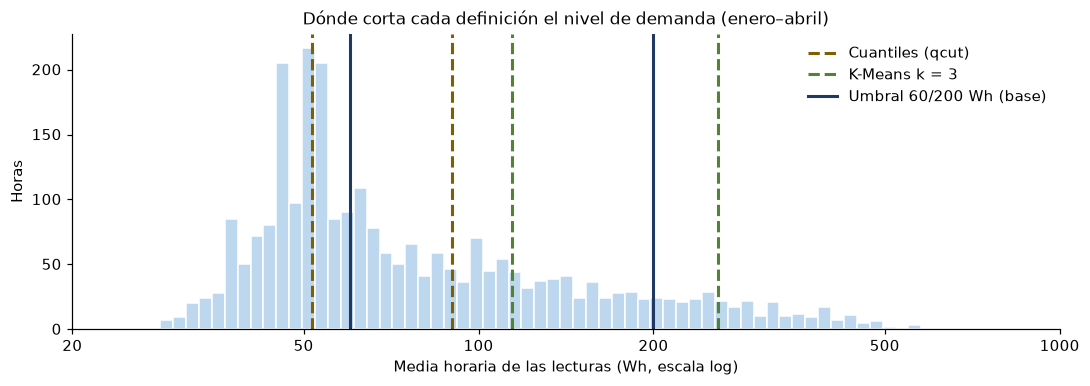

In [4]:
# Cortes de cada definición sobre la distribución de la media horaria (entrenamiento)
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.hist(np.log10(TR_media), bins=60, color="#BDD7EE", edgecolor="white")
for c_, col, lab in ((CORTES_Q, "#7F6000", "Cuantiles (qcut)"), (CORTES_K, "#548235", "K-Means k = 3"),
                     ([NIVEL_BAJO, UMBRAL], AZUL, "Umbral 60/200 Wh (base)")):
    for i, v in enumerate(c_):
        ax.axvline(np.log10(v), color=col, lw=2, ls="--" if col != AZUL else "-", label=lab if i == 0 else None)
ticks = [20, 50, 100, 200, 500, 1000]
ax.set_xticks(np.log10(ticks), [str(t) for t in ticks]); ax.set_xlabel("Media horaria de las lecturas (Wh, escala log)")
ax.set_ylabel("Horas"); ax.set_title("Dónde corta cada definición el nivel de demanda (enero–abril)")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "Q8_cortes_estados.png"); plt.show()

## PASO 3 · El MDP y los dos entornos de simulación

- **MDP contado** (el del Taller 1): P(x′|x) se cuenta con `shift(-1)` sobre horas consecutivas; R es la media por estado
  con la contabilidad corregida (al aplazar se cobra la parte de valle; al ejecutar, solo el sobrecosto). Sobre él la
  **iteración de valor da π\***, la respuesta correcta.
- **Entorno de réplica** (principal, «el dataset como simulador»): cada episodio es un **día real** de entrenamiento
  recorrido hora a hora con su energía real. La acción solo mueve la energía aplazable y la carga pendiente.
- **Entorno modelo** (control): s′ se sortea de P contada y r es la media del estado. Es *exactamente* el MDP que resolvió
  la iteración de valor, así que Q-learning debe converger a π\*.

In [5]:
class MDP:
    """MDP tabular de Shiro sobre un subconjunto de horas consecutivas (las del Taller 1 cuando defn = umbral)."""
    def __init__(self, Hs, defn_k, r_punta=R_PUNTA, lam=LAMBDA, contab="corregida"):
        dfn = DEFS[defn_k]; col = f"x_{defn_k}"
        self.k, self.DE, self.lam, self.r_punta = defn_k, dfn["DE"], lam, r_punta
        self.X = sorted(Hs[col].unique()); self.xi = {x: i for i, x in enumerate(self.X)}
        nX = len(self.X); self.nX, self.nS = nX, 2 * nX
        self.S = [f"{x}-{p}" for x in self.X for p in (0, 1)]
        sig = Hs[[col, "ts"]].shift(-1)
        ok = (sig["ts"] - Hs["ts"]) == pd.Timedelta(hours=1)
        self.P = np.zeros((nX, nX))
        for a_, b_ in zip(Hs.loc[ok, col], sig.loc[ok, col]):
            self.P[self.xi[a_], self.xi[b_]] += 1
        sin_salida = self.P.sum(1) == 0
        self.P[sin_salida, np.flatnonzero(sin_salida)] = 1          # (no ocurre con datos contiguos)
        self.P /= self.P.sum(1, keepdims=True)
        self.E = Hs.groupby(col)["wh"].mean().reindex(self.X).values / 1000
        self.F = np.array([partes(x)[1] for x in self.X]); self.N = np.array([partes(x)[2] for x in self.X])
        self.TAR = np.where(self.F == 0, 1.0, r_punta)
        de = self.DE / 1000
        self.VALID = np.zeros((self.nS, 3), bool); self.P2 = np.zeros((self.nS, 3), int)
        self.R = np.full((self.nS, 3), np.nan)
        for i in range(nX):
            for p in (0, 1):
                s = 2 * i + p; tar, e = self.TAR[i], self.E[i]
                self.VALID[s] = [True, self.N[i] == 2 and p == 0, p == 1]
                self.P2[s] = [p, 1, 0]
                costo = ([tar * e, tar * (e - de) + 1.0 * de, tar * e + (tar - 1.0) * de] if contab == "corregida"
                         else [tar * e, tar * (e - de), tar * (e + de)])
                for a in range(3):
                    if self.VALID[s, a]:
                        self.R[s, a] = -costo[a] - lam * self.P2[s, a]
        self.decision = np.flatnonzero(self.VALID.sum(1) > 1)          # estados con algo que decidir

def iteracion_valor(m, gamma=GAMMA, theta=THETA):
    """Iteración de valor del Taller 1 (mismo algoritmo, escrito con matrices)."""
    V = np.zeros(m.nS); it = 0; xs = np.repeat(np.arange(m.nX), 2)
    while True:
        it += 1
        EV = np.stack([m.P @ V[0::2], m.P @ V[1::2]], 1)               # valor esperado por x y pendiente siguiente
        Q = np.where(m.VALID, m.R + gamma * EV[xs[:, None], m.P2], -np.inf)
        Vn = Q.max(1)
        if np.abs(Vn - V).max() < theta:
            return Vn, Q, it
        V = Vn

def politica_de(Q, VALID, visitas=None):
    """Acción voraz; empates (y acciones nunca probadas) → No actuar."""
    Qm = np.where(VALID if visitas is None else (VALID & (visitas > 0)), Q, -np.inf)
    mejor = Qm.max(1); pol = Qm.argmax(1)
    pol[(Qm[:, 0] >= mejor - 1e-12) | ~np.isfinite(mejor)] = 0
    return pol

TR, TE = H[H.train].reset_index(drop=True), H[~H.train].reset_index(drop=True)
def brechas(Q, m):
    """Importancia de cada decisión: Q de la mejor acción menos Q de la segunda (0 si no hay nada que decidir)."""
    g = np.zeros(m.nS)
    for s in m.decision:
        q = np.sort(Q[s, m.VALID[s]]); g[s] = q[-1] - q[-2]
    return g

MDPS = {k: MDP(TR, k) for k in DEFS}
PI, VSTAR, BRECHA = {}, {}, {}
for k, m in MDPS.items():
    V, Q, it = iteracion_valor(m); PI[(k, GAMMA)] = politica_de(Q, m.VALID); VSTAR[(k, GAMMA)] = V
    BRECHA[(k, GAMMA)] = brechas(Q, m)
    print(f"{DEFS[k]['nombre']:<26} {m.nS} estados ({len(m.decision)} con decisión) · VI en {it} iteraciones · aplaza en "
          f"{(PI[(k, GAMMA)] == 1).sum()} estados")
    reg(f"n_estados_{k}", m.nS, es(m.nS, 0)); reg(f"n_decision_{k}", len(m.decision), es(len(m.decision), 0))
    reg(f"vi_aplaza_{k}", int((PI[(k, GAMMA)] == 1).sum()), es(int((PI[(k, GAMMA)] == 1).sum()), 0))
    if k == "umbral":
        reg("vi_iter", it, es(it, 0))
gU = BRECHA[("umbral", GAMMA)][MDPS["umbral"].decision]
print(f"Brecha entre la mejor y la segunda acción de π* en los estados con decisión: mediana {np.median(gU):.3f}, "
      f"mínimo {gU.min():.3f}, máximo {gU.max():.3f} kWh-eq")
reg("brecha_med", float(np.median(gU)), es(float(np.median(gU)), 3) + " kWh-eq"); reg("brecha_min", float(gU.min()), es(float(gU.min()), 3) + " kWh-eq")
reg("brecha_max", float(gU.max()), es(float(gU.max()), 3) + " kWh-eq")
for g in (0.5, 0.9, 0.99):
    V, Q, it = iteracion_valor(MDPS["umbral"], gamma=g); PI[("umbral", g)] = politica_de(Q, MDPS["umbral"].VALID)
    BRECHA[("umbral", g)] = brechas(Q, MDPS["umbral"])
    print(f"π* con γ = {g}: aplaza en {(PI[('umbral', g)] == 1).sum()} estados ({it} iteraciones)")
    reg(f"vi_aplaza_g{str(g).replace('.', 'p')}", int((PI[("umbral", g)] == 1).sum()), es(int((PI[("umbral", g)] == 1).sum()), 0))

Umbral 60/200 Wh (base)    40 estados (26 con decisión) · VI en 268 iteraciones · aplaza en 6 estados
Cuantiles (qcut)           24 estados (16 con decisión) · VI en 268 iteraciones · aplaza en 1 estados
K-Means                    40 estados (26 con decisión) · VI en 268 iteraciones · aplaza en 6 estados
Brecha entre la mejor y la segunda acción de π* en los estados con decisión: mediana 0.037, mínimo 0.012, máximo 0.146 kWh-eq
π* con γ = 0.5: aplaza en 6 estados (21 iteraciones)
π* con γ = 0.9: aplaza en 6 estados (131 iteraciones)
π* con γ = 0.99: aplaza en 5 estados (1359 iteraciones)


In [6]:
def repetir(pol, m, tramo, r_punta=R_PUNTA):
    """Recorre un tramo real hora a hora con la política pol (vector sobre m.S). Costo real a la tarifa de la hora."""
    col = f"x_{m.k}"; p = 0; filas = []; DE = m.DE
    for row in tramo[[col, "franja", "wh", "dia"]].itertuples(index=False):
        x, f, wh, dia = row
        s = m.xi.get(x); a = 0
        if s is not None:
            s = 2 * s + p; a = int(pol[s]) if m.VALID[s, int(pol[s])] else 0
        tar = 1.0 if f == 0 else r_punta
        e = wh + (-DE if a == 1 else (DE if a == 2 else 0))
        p = 1 if a == 1 else (0 if a == 2 else p)
        filas.append((dia, tar * e / 1000, p, int(a == 1), int(s is None)))
    if p == 1:
        dia, c, e_, ap, de_ = filas[-1]; filas[-1] = (dia, c + (1.0 if tramo.franja.iloc[-1] == 0 else r_punta) * DE / 1000, e_, ap, de_)
    return pd.DataFrame(filas, columns=["dia", "costo", "espera", "aplaza", "desconocido"]).groupby("dia").sum()

def resumen_mayo(pol, m, tramo=None, lam=LAMBDA):
    tramo = TE if tramo is None else tramo
    dd = repetir(pol, m, tramo); base = repetir(np.zeros(m.nS, int), m, tramo)
    return {"ahorro": (1 - dd.costo.sum() / base.costo.sum()) * 100, "espera": dd.espera.mean(), "aplaz": dd.aplaza.mean(),
            "objetivo": (dd.costo + lam * dd.espera).mean(), "kwh_mov": dd.aplaza.mean() * m.DE / 1000,
            "desconocidos": int(dd.desconocido.sum()), "diarios": dd}

# Ancla: π* del Taller 1 repetida en mayo reproduce sus cifras
t1 = json.loads(RUTA_T1.read_text(encoding="utf-8"))["cifras"]
ref = resumen_mayo(PI[("umbral", GAMMA)], MDPS["umbral"])
anclas = {"ahorro_opt_te": ref["ahorro"], "espera_opt_te": ref["espera"], "aplaz_opt_te": ref["aplaz"],
          "n_estados": MDPS["umbral"].nS, "iteraciones": CIFRAS["vi_iter"]["valor"], "DE": MDPS["umbral"].DE}
for k_, v in anclas.items():
    assert abs(t1[k_]["valor"] - v) < 1e-6, f"Ancla {k_}: {v} frente a {t1[k_]['valor']}"
print(f"Anclas con el Taller 1: {len(anclas)}/{len(anclas)} coinciden (ahorro π* en mayo {ref['ahorro']:.3f} %, espera {ref['espera']:.2f} h/día)")
reg("n_anclas", len(anclas), es(len(anclas), 0))
reg("vi_ahorro_te", ref["ahorro"], es(ref["ahorro"], 2) + " %"); reg("vi_espera_te", ref["espera"], es(ref["espera"], 1) + " h/día")
reg("vi_aplaz_te", ref["aplaz"], es(ref["aplaz"], 2))

Anclas con el Taller 1: 6/6 coinciden (ahorro π* en mayo 0.594 %, espera 7.15 h/día)


'0,77'

## PASO 4 · El agente Q-learning

La regla de actualización es la del profesor: Q(s,a) ← Q(s,a) + α·[r + γ·max Q(s′,·) − Q(s,a)], con ε-greedy y
decaimiento de ε por episodio. Lo que cambia:
- la Q-table es una matriz NumPy y no un `DataFrame`;
- las acciones inválidas no se eligen;
- un episodio es un día de 24 horas y el entorno **no se reinicia** a medianoche: la carga pendiente cruza a la mañana
  siguiente, como en la vida real. Al terminar enero–abril empieza otra «pasada» por los mismos días.

**Cómo se mide si aprendió.** No basta con contar en cuántos estados coincide con π\*. En muchos estados las dos acciones
valen casi lo mismo: equivocarse ahí no cuesta nada. Por eso se usan tres medidas:
1. **Coincidencia simple:** % de los estados con decisión en que su acción coincide con π\*.
2. **Coincidencia ponderada:** cada estado pesa lo que vale acertar en él, es decir, la brecha entre la mejor y la
   segunda acción según la iteración de valor.
3. **Ahorro capturado:** qué % del ahorro de π\* consigue en mayo, con la cuenta real.

«Llegar al 90 %» es que, desde algún día simulado, la coincidencia ponderada ya no baje del 90 %; se cuenta en cuántas de las 5 semillas ocurre.

In [7]:
class EntornoReplica:
    """Recorre el tramo real en orden, SIN reiniciar: la carga pendiente cruza la medianoche como en la vida real.
    Cada episodio es un día (24 horas seguidas); al terminar el tramo empieza otra pasada desde el primer día."""
    def __init__(self, m, tramo):
        col = f"x_{m.k}"; self.m = m
        assert tramo["hora"].iloc[0] == 0 and len(tramo) % 24 == 0
        self.xi = np.array([m.xi[x] for x in tramo[col]]); self.f = tramo["franja"].values; self.e = tramo["wh"].values / 1000
        self.n = len(tramo); self.dias = self.n // 24
    def reset(self, rng):
        return 0
    def paso(self, i, p, a, rng):
        tar = 1.0 if self.f[i] == 0 else self.m.r_punta
        j = i + 1 if i + 1 < self.n else 0
        return tar, self.e[i], j, int(self.xi[j])

class EntornoModelo:
    """Cadena de Markov contada (el MDP exacto de la iteración de valor), recorrida sin reiniciar."""
    def __init__(self, m, tramo):
        self.m = m; col = f"x_{m.k}"
        x0 = tramo.loc[tramo.hora == 0, col].map(m.xi).values
        self.p0 = np.bincount(x0, minlength=m.nX) / len(x0); self.cum = m.P.cumsum(1)
    def reset(self, rng):
        return int(np.searchsorted(self.p0.cumsum(), rng.random()))
    def paso(self, x, p, a, rng):
        x2 = int(np.searchsorted(self.cum[x], rng.random())); x2 = min(x2, self.m.nX - 1)
        return self.m.TAR[x], self.m.E[x], x2, x2

def entrenar(m, entorno, alpha=ALPHA, gamma=GAMMA, n_ep=N_EP, semilla=RS, recompensa="base", pi_ref=None, pesos=None,
             eps0=EPS0, eps_min=EPS_MIN, decay=DECAY, contab="corregida"):
    """Q-learning tabular (regla del profesor). alpha: número fijo, o "1/N^0.6" (decreciente por visitas a (s, a))."""
    rng = np.random.default_rng(semilla)
    nS = m.nS; Q = np.zeros((nS, 3)); N = np.zeros((nS, 3), int)
    validas = [np.flatnonzero(m.VALID[s]).tolist() for s in range(nS)]
    de, lam = m.DE / 1000, m.lam
    es_replica = isinstance(entorno, EntornoReplica)
    alfa_fija = not isinstance(alpha, str)
    eps = eps0; h = {k: [] for k in ("r", "costo", "aplz", "eps", "acierto", "acierto_w", "g", "ahorro")}
    pos = entorno.reset(rng); x = int(entorno.xi[pos]) if es_replica else pos; p = 0
    for ep in range(n_ep):
        tot = costo_real = aplz = ref = 0.0
        for t in range(24):
            s = 2 * x + p; va = validas[s]
            if rng.random() < eps:
                a = va[int(rng.random() * len(va))]
            else:
                a = max(va, key=lambda a_: Q[s, a_])                   # empate → la primera (No actuar)
            tar, e, pos2, x2 = entorno.paso(pos, p, a, rng)
            if not es_replica:
                e = m.E[x]
            # recompensa base (contabilidad del Taller 1)
            if a == 0:
                c = tar * e; p2 = p
            elif a == 1:
                c = (tar * (e - de) + 1.0 * de) if contab == "corregida" else tar * (e - de); p2 = 1
            else:
                c = (tar * e + (tar - 1.0) * de) if contab == "corregida" else tar * (e + de); p2 = 0
            r = -c - lam * p2
            if recompensa == "transaccion":
                r = 1.0 if a in (1, 2) else 0.0
            elif recompensa == "miedo":
                neta = r - (-tar * e)                                  # frente a no actuar sin carga pendiente
                r = -1000.0 if neta < -1e-12 else neta
            costo_real += tar * (e - de if a == 1 else (e + de if a == 2 else e)); aplz += a == 1
            ref += tar * e                                             # costo de no actuar ese mismo día
            s2 = 2 * x2 + p2
            q2 = max(Q[s2, a_] for a_ in validas[s2])
            N[s, a] += 1
            al = alpha if alfa_fija else 1.0 / N[s, a] ** 0.6
            Q[s, a] += al * (r + gamma * q2 - Q[s, a])
            tot += r; x, p, pos = x2, p2, pos2
        h["r"].append(tot); h["costo"].append(costo_real); h["aplz"].append(aplz); h["eps"].append(eps)
        h["g"].append(tot + ref if recompensa == "base" else tot)    # recompensa del día menos la de no actuar
        h["ahorro"].append(ref - costo_real)                           # ahorro real del día (kWh-eq)
        eps = max(eps_min, eps * decay)
        if pi_ref is not None and (ep + 1) % CADA == 0:
            pol = politica_de(Q, m.VALID, N); ok_ = pol[m.decision] == pi_ref[m.decision]
            h["acierto"].append(ok_.mean() * 100)
            if pesos is not None:
                w = pesos[m.decision]; h["acierto_w"].append((w * ok_).sum() / w.sum() * 100)
    out = {k: np.array(v) for k, v in h.items()}
    out.update({"Q": Q, "N": N, "pol": politica_de(Q, m.VALID, N)})
    return out

def dias_hasta(acierto, umbral=90):
    if len(acierto) == 0:
        return np.nan
    bajo = np.flatnonzero(acierto < umbral)
    k = 0 if len(bajo) == 0 else bajo[-1] + 1
    return np.nan if k >= len(acierto) else (k + 1) * CADA

def correr(m, entorno, etiqueta, pi_ref=None, pesos=None, **kw):
    t0 = time.time(); corridas = [entrenar(m, entorno, semilla=s_, pi_ref=pi_ref, pesos=pesos, **kw) for s_ in SEMILLAS]
    print(f"  {etiqueta:<40} {time.time() - t0:5.1f} s", end="")
    if pi_ref is not None:
        fin = [c["acierto"][-1] for c in corridas]; fw = [c["acierto_w"][-1] for c in corridas]
        dh = np.array([dias_hasta(c["acierto_w"]) for c in corridas]); alc = int((~np.isnan(dh)).sum())
        print(f" · coincidencia {np.mean(fin):5.1f} % · ponderada {np.mean(fw):5.1f} % (rango {min(fw):.0f}–{max(fw):.0f})"
              f" · llegan al 90 % ponderado: {alc} de {len(corridas)} semillas", end="")
    print()
    return corridas
print("Agente listo.")

Agente listo.


In [8]:
def banda(ax, corridas, campo, color, etiqueta, suave=True, x=None):
    M = np.array([pd.Series(c[campo]).rolling(VENTANA, min_periods=1).mean().values if suave else c[campo] for c in corridas])
    x = np.arange(1, M.shape[1] + 1) if x is None else x
    ax.plot(x, M.mean(0), color=color, lw=1.6, label=etiqueta)
    ax.fill_between(x, M.min(0), M.max(0), color=color, alpha=0.18)

def fig_experimento(res, archivo, titulo, acierto=True):
    n = 3 if acierto else 2
    fig, axs = plt.subplots(1, n, figsize=(5.2 * n, 3.7))
    for j, (lab, cor) in enumerate(res.items()):
        col = PALETA[j % len(PALETA)]
        banda(axs[0], cor, "g", col, lab)
        if acierto:
            banda(axs[1], cor, "acierto_w", col, lab, suave=False, x=np.arange(1, len(cor[0]["acierto_w"]) + 1) * CADA)
    axs[0].axhline(0, color="#999", lw=0.8)
    axs[0].set(title="Curva de aprendizaje (media móvil de 100 días)", xlabel="Episodio (día simulado)",
               ylabel="Recompensa del día − la de no actuar\n(kWh-eq; banda = 5 semillas)")
    if acierto:
        axs[1].set(title="Coincidencia con π*, ponderada por la brecha", xlabel="Episodio", ylabel="% (ponderado)", ylim=(0, 105))
        axs[1].axhline(90, color="#999", ls=":", lw=1)
    eps_largo = max((next(iter(res.values()))[0]["eps"], *[c[0]["eps"] for c in res.values()]), key=len)
    axs[-1].plot(eps_largo, color="#7F6000"); axs[-1].set(title="Decaimiento de ε (mismo calendario en todas)", xlabel="Episodio", ylabel="ε")
    axs[0].legend(frameon=False, fontsize=8)
    fig.suptitle(titulo, fontsize=11, y=1.02); fig.tight_layout(); fig.savefig(FIG / archivo, bbox_inches="tight"); plt.show()

def matriz_q(Q, m):
    """nX × 4: [no·libre, aplazar·libre, no·pendiente, ejecutar·pendiente]."""
    M = np.full((m.nX, 4), np.nan)
    for i in range(m.nX):
        for j, (p, a) in enumerate(((0, 0), (0, 1), (1, 0), (1, 2))):
            if m.VALID[2 * i + p, a]:
                M[i, j] = Q[2 * i + p, a]
    return M

def fig_heatmaps(paneles, archivo, titulo):
    """paneles: lista de (etiqueta, Q medio, mdp). Número = valor Q; color = ventaja frente a la mejor acción del estado."""
    n = len(paneles); fig, axs = plt.subplots(1, n, figsize=(3.6 * n + 1.6, 0.36 * max(p[2].nX for p in paneles) + 1.8))
    axs = np.atleast_1d(axs)
    for ax, (lab, Q, m) in zip(axs, paneles):
        M = matriz_q(Q, m); V = np.full_like(M, np.nan)
        for i in range(m.nX):
            for c0, c1 in ((0, 2), (2, 4)):
                fila = M[i, c0:c1]
                if np.isfinite(fila).any():
                    V[i, c0:c1] = fila - np.nanmax(fila)
        ax.imshow(np.nan_to_num(V, nan=0.0), cmap="RdYlGn", vmin=-0.3, vmax=0, aspect="auto")
        for i in range(m.nX):
            for j in range(4):
                ax.text(j, i, "—" if np.isnan(M[i, j]) else f"{M[i, j]:.1f}", ha="center", va="center", fontsize=6.5,
                        color="#666" if np.isnan(M[i, j]) else "black")
        ax.set_xticks(range(4), ["No act.\nlibre", "Aplazar\nlibre", "No act.\npendiente", "Ejecutar\npendiente"], fontsize=7)
        ax.set_yticks(range(m.nX), [describir(x, DEFS[m.k]["tipo"]) for x in m.X], fontsize=7)
        ax.set_title(lab, fontsize=9)
        if ax is not axs[0]:
            ax.set_yticklabels([])
    fig.suptitle(titulo + "\n(número = valor Q; verde = mejor acción del estado; rojo = peor)", fontsize=10)
    fig.tight_layout(); fig.savefig(FIG / archivo, bbox_inches="tight"); plt.show()

def q_medio(corridas):
    return np.mean([c["Q"] for c in corridas], 0)

def pol_consenso(corridas, m):
    votos = np.array([c["pol"] for c in corridas])
    return np.array([np.bincount(votos[:, s], minlength=3).argmax() for s in range(m.nS)])

def resumen_corridas(corridas, m, pi_ref, clave, etiqueta, tramo=None):
    """Registra coincidencias, días hasta 90 %, ahorro capturado y la repetición de mayo (media de las 5 semillas)."""
    ev = [resumen_mayo(c["pol"], m, tramo) for c in corridas]
    ref_ahorro = resumen_mayo(pi_ref, m, tramo)["ahorro"] if pi_ref is not None else np.nan
    out = {"Configuración": etiqueta}
    if pi_ref is not None:
        fin = [c["acierto"][-1] for c in corridas]; fw = [c["acierto_w"][-1] for c in corridas]
        dh = np.array([dias_hasta(c["acierto_w"]) for c in corridas]); alc = int((~np.isnan(dh)).sum())
        out["Coincidencia (%)"] = np.mean(fin); out["Coincidencia ponderada (%)"] = np.mean(fw)
        out["Semillas que llegan al 90 %"] = alc
        reg(f"{clave}_acierto", np.mean(fin), es(np.mean(fin), 1) + " %"); reg(f"{clave}_acierto_w", np.mean(fw), es(np.mean(fw), 1) + " %")
        reg(f"{clave}_acierto_w_min", min(fw), es(min(fw), 0) + " %"); reg(f"{clave}_acierto_w_max", max(fw), es(max(fw), 0) + " %")
        reg(f"{clave}_alcanzan", alc, f"{alc} de {len(corridas)}")
        reg(f"{clave}_dias90", None if alc == 0 else float(np.nanmedian(dh)),
            "ninguna semilla" if alc == 0 else f"{alc} de {len(corridas)} semillas (mediana {es(float(np.nanmedian(dh)), 0)} días)")
    for campo, dec, uni in (("ahorro", 2, " %"), ("espera", 1, " h/día"), ("aplaz", 2, ""), ("objetivo", 3, " kWh-eq/día")):
        v = np.mean([e[campo] for e in ev]); out[f"Mayo · {campo}"] = v
        reg(f"{clave}_{campo}", v, es(v, dec) + uni)
    reg(f"{clave}_ahorro_min", min(e["ahorro"] for e in ev), es(min(e["ahorro"] for e in ev), 2) + " %")
    reg(f"{clave}_ahorro_max", max(e["ahorro"] for e in ev), es(max(e["ahorro"] for e in ev), 2) + " %")
    if pi_ref is not None and ref_ahorro > 0:
        cap = out["Mayo · ahorro"] / ref_ahorro * 100; out["Ahorro capturado de π* (%)"] = cap
        reg(f"{clave}_captura", cap, es(cap, 0) + " %")
    return out
TABLA = []
print("Ayudas de gráficas listas.")

Ayudas de gráficas listas.


## PASO 5 · Problema base: ¿Q-learning recupera la π\* del Taller 1?

Se comparan dos agentes, cada uno en dos entornos:
- **Agente del profesor:** α = 0,1 fijo y 5.000 días simulados.
- **Agente recomendado para Shiro:** α decreciente (1/N^0,6, donde N son las visitas a cada par estado-acción) y 15.000
  días simulados. El α decreciente es la condición clásica de convergencia de Q-learning: al principio aprende rápido y
  después promedia, en lugar de seguir saltando con cada día raro.

El **entorno modelo** es el mismo MDP que resolvió la iteración de valor, así que ahí debe llegar a π\*. En el **entorno
de réplica** (días reales) la diferencia restante la explica que la realidad no es exactamente el MDP de Markov contado.

Días de entrenamiento por pasada: 110


  Profesor (α 0,1 · 5.000 días) · modelo     5.9 s · coincidencia  54.6 % · ponderada  58.6 % (rango 50–67) · llegan al 90 % ponderado: 0 de 5 semillas


  Profesor (α 0,1 · 5.000 días) · réplica    3.7 s · coincidencia  54.6 % · ponderada  67.3 % (rango 50–74) · llegan al 90 % ponderado: 0 de 5 semillas


  Recomendado (1/N^0,6 · 15.000) · modelo   23.1 s · coincidencia  66.9 % · ponderada  73.7 % (rango 54–92) · llegan al 90 % ponderado: 1 de 5 semillas


  Recomendado (1/N^0,6 · 15.000) · réplica  32.5 s · coincidencia  73.1 % · ponderada  84.7 % (rango 82–88) · llegan al 90 % ponderado: 0 de 5 semillas


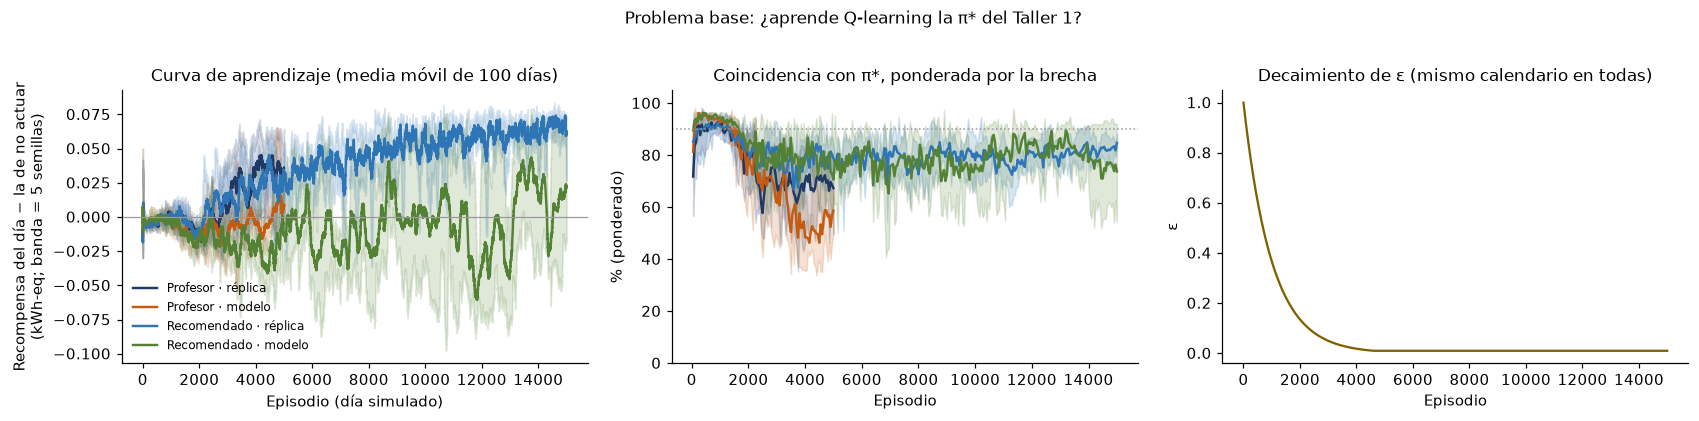

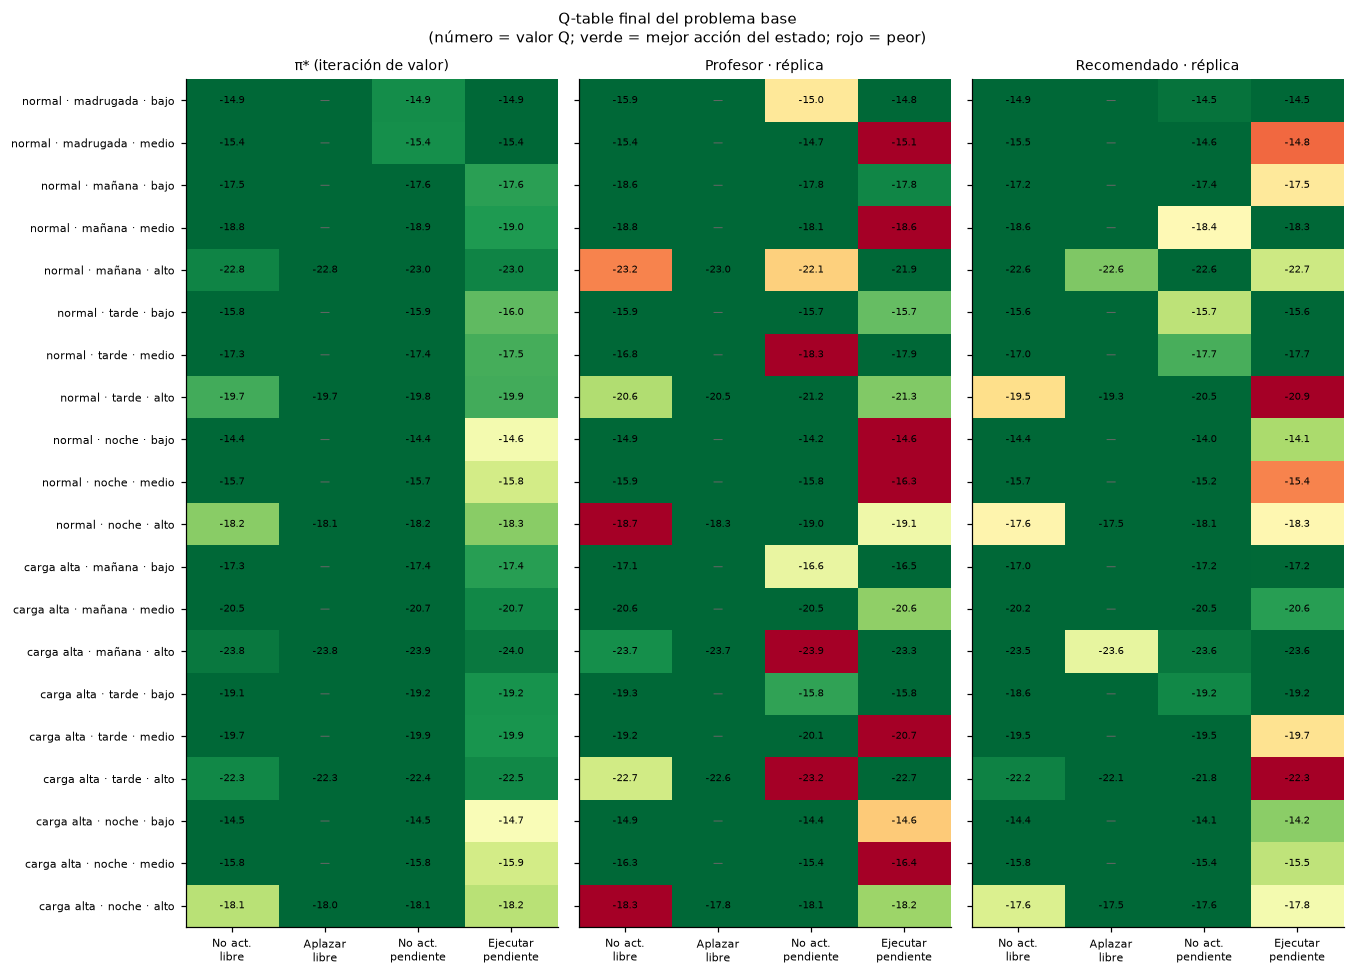

Profesor: error medio |Q − Q*| = 0.513 kWh-eq (sesgo -0.016) frente a una brecha mediana de 0.037
Recomendado: error medio |Q − Q*| = 0.324 kWh-eq (sesgo +0.251) frente a una brecha mediana de 0.037
Estados donde el consenso del agente recomendado (réplica) difiere de π*:
   normal · madrugada · medio · pendiente: Q-learning «No actuar» · π* «Ejecutar» · brecha 0.025
   normal · mañana · medio · pendiente: Q-learning «Ejecutar» · π* «No actuar» · brecha 0.032
   normal · mañana · alto: Q-learning «No actuar» · π* «Aplazar» · brecha 0.018
   normal · tarde · bajo · pendiente: Q-learning «Ejecutar» · π* «No actuar» · brecha 0.058
   normal · tarde · medio · pendiente: Q-learning «Ejecutar» · π* «No actuar» · brecha 0.047
   carga alta · mañana · bajo · pendiente: Q-learning «Ejecutar» · π* «No actuar» · brecha 0.036
   carga alta · mañana · alto: Q-learning «No actuar» · π* «Aplazar» · brecha 0.012


In [9]:
mU = MDPS["umbral"]; piU = PI[("umbral", GAMMA)]; wU = BRECHA[("umbral", GAMMA)]
ENV_R = EntornoReplica(mU, TR); ENV_M = EntornoModelo(mU, TR)
print(f"Días de entrenamiento por pasada: {ENV_R.dias}")
REC = dict(alpha=ALPHA_REC, n_ep=N_EP_REC)
PROF_M = correr(mU, ENV_M, "Profesor (α 0,1 · 5.000 días) · modelo", pi_ref=piU, pesos=wU)
PROF = correr(mU, ENV_R, "Profesor (α 0,1 · 5.000 días) · réplica", pi_ref=piU, pesos=wU)
BASE_M = correr(mU, ENV_M, "Recomendado (1/N^0,6 · 15.000) · modelo", pi_ref=piU, pesos=wU, **REC)
BASE = correr(mU, ENV_R, "Recomendado (1/N^0,6 · 15.000) · réplica", pi_ref=piU, pesos=wU, **REC)
for cor, k, et in ((PROF_M, "prof_modelo", "Profesor · entorno modelo"), (PROF, "prof", "Profesor · réplica de días reales"),
                   (BASE_M, "rec_modelo", "Recomendado · entorno modelo"), (BASE, "base", "Recomendado · réplica de días reales")):
    TABLA.append(resumen_corridas(cor, mU, piU, k, et))
fig_experimento({"Profesor · réplica": PROF, "Profesor · modelo": PROF_M, "Recomendado · réplica": BASE,
                 "Recomendado · modelo": BASE_M}, "Q1_base_aprendizaje.png",
                "Problema base: ¿aprende Q-learning la π* del Taller 1?")
fig_heatmaps([("π* (iteración de valor)", iteracion_valor(mU)[1], mU), ("Profesor · réplica", q_medio(PROF), mU),
              ("Recomendado · réplica", q_medio(BASE), mU)], "Q2_base_heatmap.png", "Q-table final del problema base")
# Diagnóstico: error de los valores Q frente a la brecha entre acciones
Qstar = iteracion_valor(mU)[1]
for nom, cor in (("Profesor", PROF), ("Recomendado", BASE)):
    err = np.abs(q_medio(cor) - Qstar)[mU.VALID].mean(); sesgo = (q_medio(cor) - Qstar)[mU.VALID].mean()
    print(f"{nom}: error medio |Q − Q*| = {err:.3f} kWh-eq (sesgo {sesgo:+.3f}) frente a una brecha mediana de {np.median(wU[mU.decision]):.3f}")
    reg(f"{'prof' if nom == 'Profesor' else 'base'}_errq", err, es(err, 2) + " kWh-eq"); reg(f"{'prof' if nom == 'Profesor' else 'base'}_sesgoq", sesgo, es(sesgo, 2) + " kWh-eq")
pc = pol_consenso(BASE, mU)
dif = [(describir(mU.S[s]), ACCIONES[pc[s]], ACCIONES[piU[s]], wU[s]) for s in mU.decision if pc[s] != piU[s]]
print("Estados donde el consenso del agente recomendado (réplica) difiere de π*:")
for d_, a1, a2, g_ in dif:
    print(f"   {d_}: Q-learning «{a1}» · π* «{a2}» · brecha {g_:.3f}")
reg("base_n_difs", len(dif), es(len(dif), 0)); reg("ventana", VENTANA, es(VENTANA, 0)); reg("n_ep", N_EP, es(N_EP, 0))
reg("n_ep_rec", N_EP_REC, es(N_EP_REC, 0)); reg("n_semillas", len(SEMILLAS), es(len(SEMILLAS), 0)); reg("dias_ep", ENV_R.dias, es(ENV_R.dias, 0))
reg("anos_rec", N_EP_REC / 365, es(N_EP_REC / 365, 0) + " años"); reg("anos_prof", N_EP / 365, es(N_EP / 365, 0) + " años")
pd.DataFrame({"Estado": mU.S, "Descripción": [describir(s) for s in mU.S], "Q-learning recomendado (consenso)": [ACCIONES[a] for a in pc],
              "π* (iteración de valor)": [ACCIONES[a] for a in piU], "Brecha de π* (kWh-eq)": wU}).to_csv(
    "politicas_base.csv", index=False, encoding="utf-8")

## Parte 1 · El explorador de entornos: ¿la política es la misma en otra estación?

- **Problema A:** el agente aprende con **enero–abril** (invierno).
- **Problema B:** el agente aprende **solo con mayo** (primavera; 26 días).

Cada uno se compara con la π\* que la iteración de valor obtiene con los datos de su propio periodo. Después se cruzan:
la política de invierno se aplica en mayo y la de mayo en enero–abril. La «personalidad» de cada periodo se mide con
cuántas horas altas tiene, qué tan lejos queda el valle y cuántos días son de carga alta. Ambos usan el agente
recomendado.

Mayo: 19 combinaciones exógenas (38 estados) · 26 días por pasada


  Problema B · solo mayo                    26.8 s · coincidencia  72.8 % · ponderada  76.2 % (rango 71–84) · llegan al 90 % ponderado: 0 de 5 semillas
        Periodo  Horas con nivel alto (%)  Días con carga alta estimada (%)  Energía media (kWh/día)  Horas al valle desde la tarde  Horas al valle desde la noche  Estados vistos
Enero–abril (A)                     10.91                             50.91                    14.18                          11.99                           5.09              40
       Mayo (B)                      8.33                             57.69                    13.39                          11.71                           5.35              38
                                 Estado π* invierno   π* mayo Q-learning invierno Q-learning mayo
  normal · madrugada · bajo · pendiente    Ejecutar  Ejecutar            Ejecutar       No actuar
 normal · madrugada · medio · pendiente    Ejecutar  Ejecutar           No actuar       No actuar
     normal · mañ

Aplicada en          enero–abril   mayo
Política                               
Q-learning invierno        0.533  0.531
Q-learning mayo            0.000  0.000
π* invierno                0.602  0.594
π* mayo                    0.602  0.594


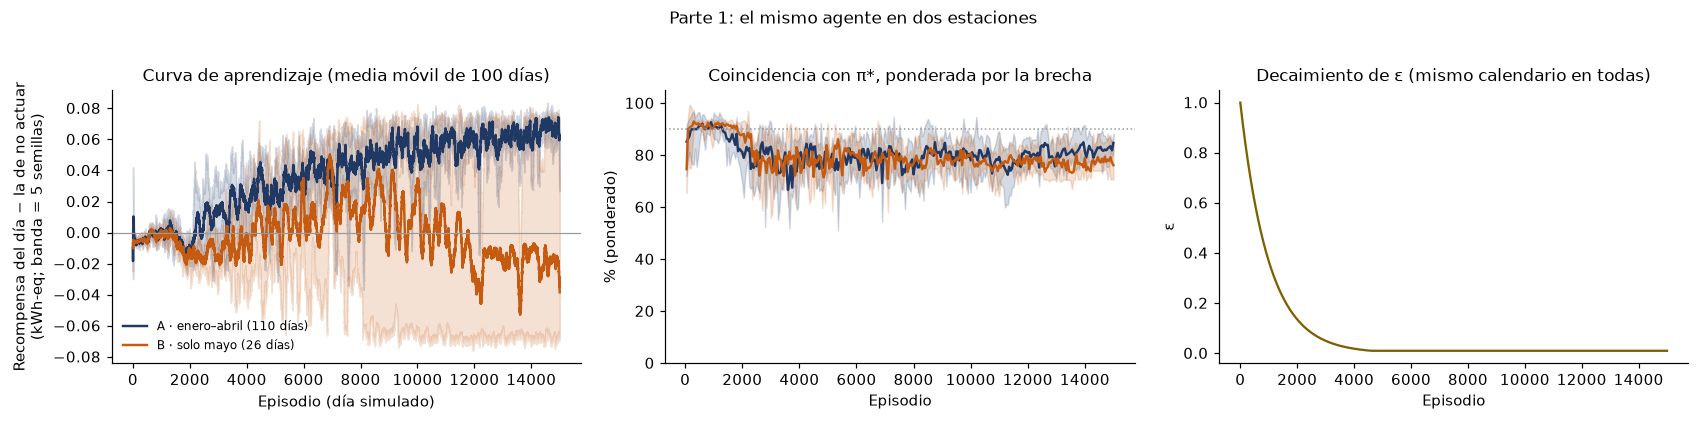

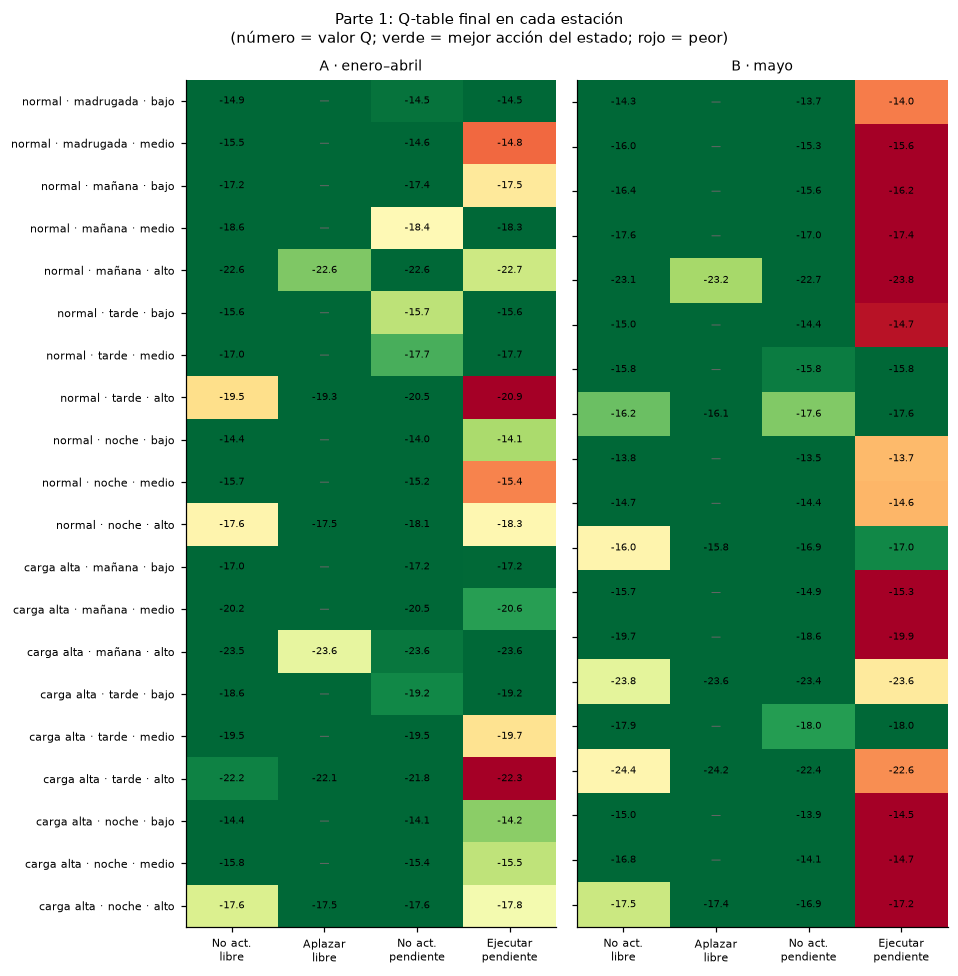

In [10]:
mB = MDP(TE, "umbral")
VB, QB_, _ = iteracion_valor(mB); piB = politica_de(QB_, mB.VALID); wB = brechas(QB_, mB)
ENV_B = EntornoReplica(mB, TE)
print(f"Mayo: {mB.nX} combinaciones exógenas ({mB.nS} estados) · {ENV_B.dias} días por pasada")
B = correr(mB, ENV_B, "Problema B · solo mayo", pi_ref=piB, pesos=wB, **REC)

def horas_valle(m):
    obj = [i for i in range(m.nX) if m.F[i] == 0]; resto = [i for i in range(m.nX) if m.F[i] != 0]
    Q_ = m.P[np.ix_(resto, resto)]; t_ = np.linalg.solve(np.eye(len(resto)) - Q_, np.ones(len(resto)))
    return dict(zip([m.X[i] for i in resto], t_))
pers = []
for nom, m, tramo in (("Enero–abril (A)", mU, TR), ("Mayo (B)", mB, TE)):
    hv = horas_valle(m); fr = tramo.groupby("franja")["x_umbral"].apply(lambda s: np.mean([hv.get(x, 0) for x in s]))
    pers.append({"Periodo": nom, "Horas con nivel alto (%)": (tramo["nivel_umbral"] == 2).mean() * 100,
                 "Días con carga alta estimada (%)": tramo.groupby("dia")["tipo"].max().mean() * 100,
                 "Energía media (kWh/día)": tramo.groupby("dia")["wh"].sum().mean() / 1000,
                 "Horas al valle desde la tarde": fr.get(2, np.nan), "Horas al valle desde la noche": fr.get(3, np.nan),
                 "Estados vistos": m.nS})
df_pers = pd.DataFrame(pers); print(df_pers.round(2).to_string(index=False))
for r_, k in zip(pers, ("A", "B")):
    reg(f"pers_alto_{k}", r_["Horas con nivel alto (%)"], es(r_["Horas con nivel alto (%)"]) + " %")
    reg(f"pers_calto_{k}", r_["Días con carga alta estimada (%)"], es(r_["Días con carga alta estimada (%)"]) + " %")
    reg(f"pers_kwh_{k}", r_["Energía media (kWh/día)"], es(r_["Energía media (kWh/día)"]) + " kWh/día")
    reg(f"pers_valle_tarde_{k}", r_["Horas al valle desde la tarde"], es(r_["Horas al valle desde la tarde"]) + " h")
    reg(f"pers_valle_noche_{k}", r_["Horas al valle desde la noche"], es(r_["Horas al valle desde la noche"]) + " h")
    reg(f"pers_estados_{k}", r_["Estados vistos"], es(r_["Estados vistos"], 0))

idxA = {s: i for i, s in enumerate(mU.S)}; idxB = {s: i for i, s in enumerate(mB.S)}
decB = [s for s in mB.S if s in idxA and mU.VALID[idxA[s]].sum() > 1]
pcA, pcB = pol_consenso(BASE, mU), pol_consenso(B, mB)
filas = [{"Estado": describir(s), "π* invierno": ACCIONES[piU[idxA[s]]], "π* mayo": ACCIONES[piB[idxB[s]]],
          "Q-learning invierno": ACCIONES[pcA[idxA[s]]], "Q-learning mayo": ACCIONES[pcB[idxB[s]]]} for s in decB]
df_p1 = pd.DataFrame(filas); print(df_p1.to_string(index=False))
iguales_vi = sum(f["π* invierno"] == f["π* mayo"] for f in filas); iguales_ql = sum(f["Q-learning invierno"] == f["Q-learning mayo"] for f in filas)
reg("p1_decision_comunes", len(decB), es(len(decB), 0)); reg("p1_iguales_vi", iguales_vi, es(iguales_vi, 0))
reg("p1_iguales_ql", iguales_ql, es(iguales_ql, 0))
df_p1.to_csv("politicas_parte1_estaciones.csv", index=False, encoding="utf-8")

def a_vector(pol_src, m_src, m_dst):
    ix = {s: i for i, s in enumerate(m_src.S)}
    return np.array([pol_src[ix[s]] if s in ix else 0 for s in m_dst.S])
trans = []
for nom, pol, m_src in (("π* invierno", piU, mU), ("π* mayo", piB, mB), ("Q-learning invierno", pcA, mU), ("Q-learning mayo", pcB, mB)):
    for tnom, tramo, m_eval in (("enero–abril", TR, mU), ("mayo", TE, mB)):
        rr = resumen_mayo(a_vector(pol, m_src, m_eval), m_eval, tramo)
        trans.append({"Política": nom, "Aplicada en": tnom, "Ahorro (%)": rr["ahorro"], "Espera (h/día)": rr["espera"]})
df_tr = pd.DataFrame(trans); print(df_tr.pivot(index="Política", columns="Aplicada en", values="Ahorro (%)").round(3).to_string())
for r_ in trans:
    k = r_["Política"].replace("π* ", "vi_").replace("Q-learning ", "ql_").replace("invierno", "inv")
    t_ = "tr" if r_["Aplicada en"].startswith("enero") else "te"
    reg(f"tr_{k}_{t_}", r_["Ahorro (%)"], es(r_["Ahorro (%)"], 2) + " %"); reg(f"tre_{k}_{t_}", r_["Espera (h/día)"], es(r_["Espera (h/día)"], 1) + " h/día")
TABLA.append(resumen_corridas(B, mB, piB, "p1_B", "Parte 1 · problema B (solo mayo)", tramo=TE))
fig_experimento({"A · enero–abril (110 días)": BASE, "B · solo mayo (26 días)": B}, "Q3_parte1_aprendizaje.png",
                "Parte 1: el mismo agente en dos estaciones")
fig_heatmaps([("A · enero–abril", q_medio(BASE), mU), ("B · mayo", q_medio(B), mB)], "Q4_parte1_heatmap.png",
             "Parte 1: Q-table final en cada estación")

## Parte 2 · El sintonizador de hiperparámetros

- **Experimento 1 (γ):** agente miope (γ = 0,5), el γ del profesor (0,9), el base (0,95) y uno paciente (0,99), todos con
  el agente recomendado. Cada uno se compara con la π\* que la iteración de valor da **para su mismo γ**.
- **Experimento 2 (α):** lento (0,01), el del profesor (0,1), impulsivo (0,9) y el decreciente recomendado, todos con
  15.000 días para compararlos en igualdad.

ε sigue el mismo calendario en todos los casos: no depende de α ni de γ.

  γ = 0.5                                   26.2 s · coincidencia  77.7 % · ponderada  77.8 % (rango 65–91) · llegan al 90 % ponderado: 1 de 5 semillas


  γ = 0.9                                   33.5 s · coincidencia  60.0 % · ponderada  72.0 % (rango 66–75) · llegan al 90 % ponderado: 0 de 5 semillas


  γ = 0.99                                  30.6 s · coincidencia  66.2 % · ponderada  81.9 % (rango 70–92) · llegan al 90 % ponderado: 1 de 5 semillas


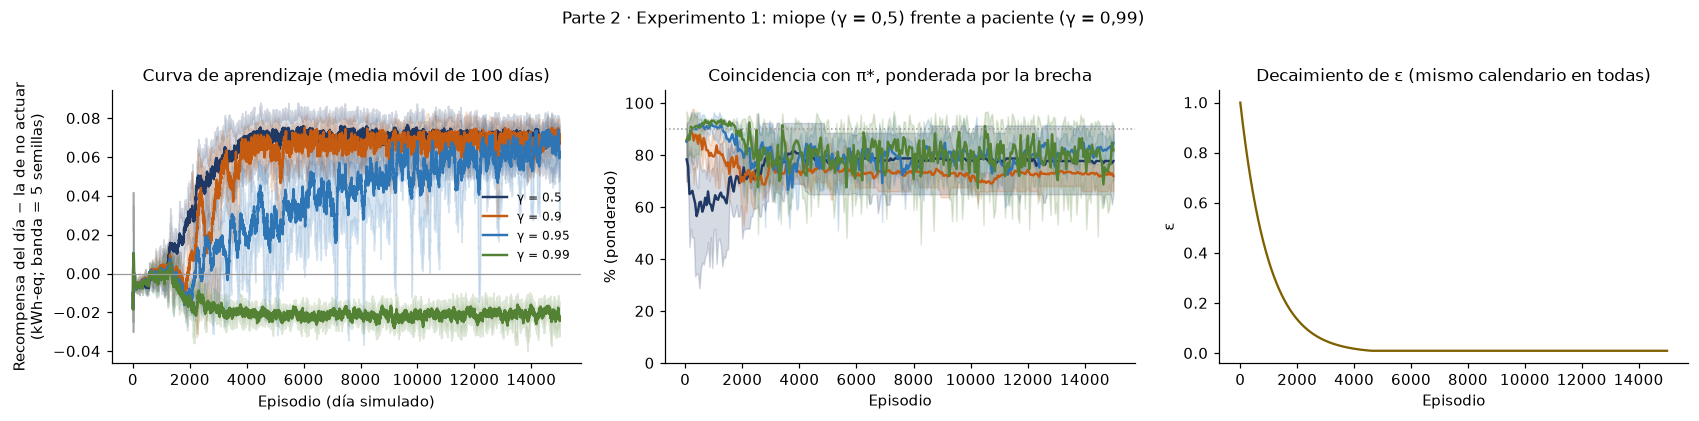

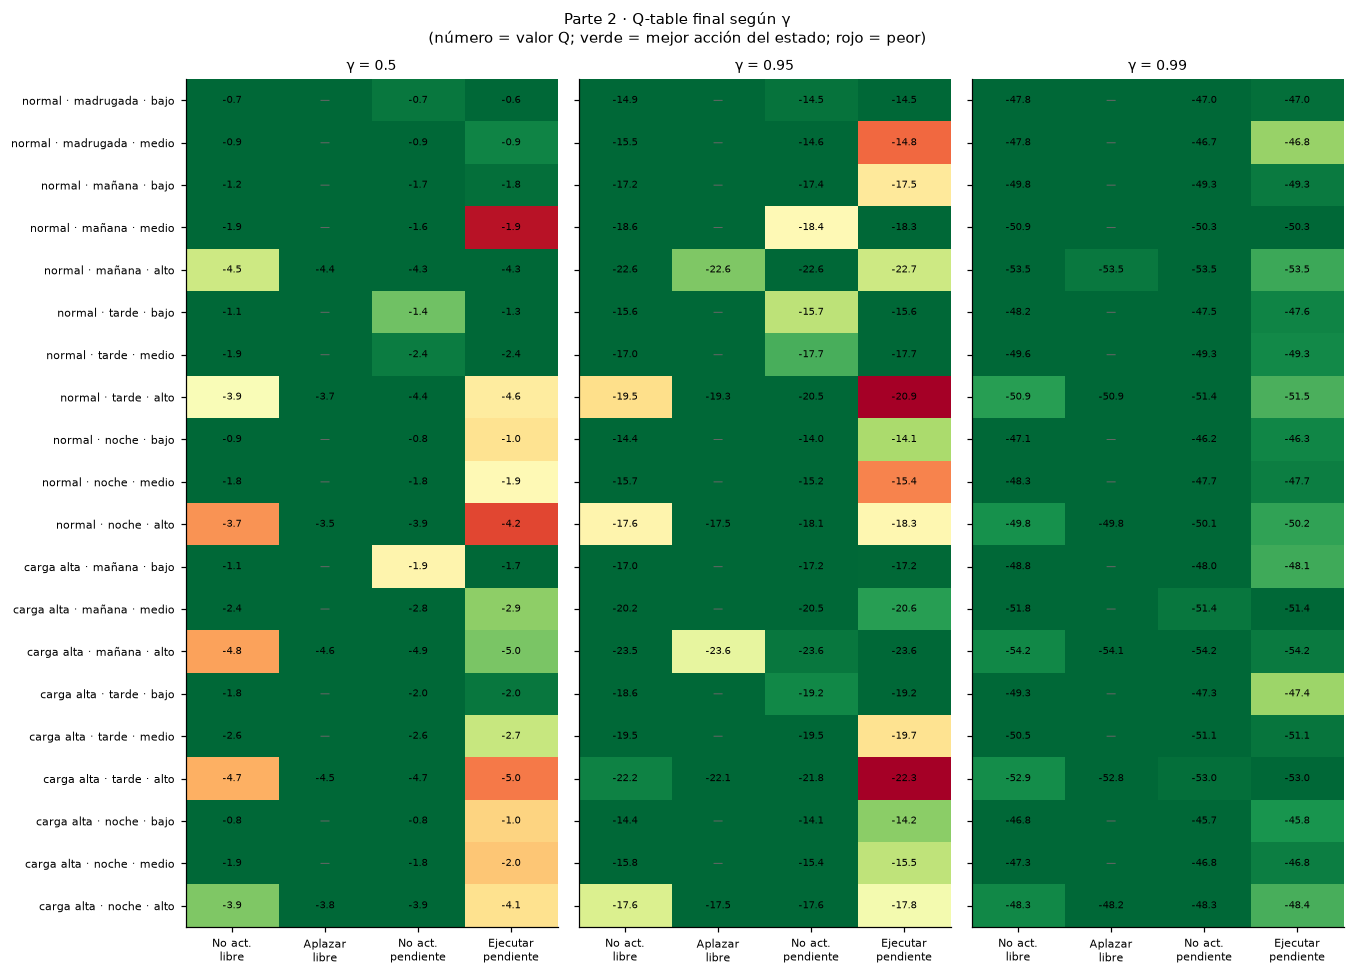

γ = 0.5: aplaza en 6 estados, ejecuta en 5; π*(γ) aplaza en 6 y ejecuta en 2 · Q mínimo -5.0
γ = 0.95: aplaza en 4 estados, ejecuta en 5; π*(γ) aplaza en 6 y ejecuta en 2 · Q mínimo -23.6
γ = 0.99: aplaza en 5 estados, ejecuta en 4; π*(γ) aplaza en 5 y ejecuta en 4 · Q mínimo -54.2


  α = 0.01 (15.000 días)                    25.1 s · coincidencia  66.9 % · ponderada  71.0 % (rango 66–79) · llegan al 90 % ponderado: 0 de 5 semillas


  α = 0.1 (15.000 días)                     23.8 s · coincidencia  50.0 % · ponderada  65.2 % (rango 59–69) · llegan al 90 % ponderado: 0 de 5 semillas


  α = 0.9 (15.000 días)                     17.2 s · coincidencia  54.6 % · ponderada  62.2 % (rango 53–77) · llegan al 90 % ponderado: 0 de 5 semillas


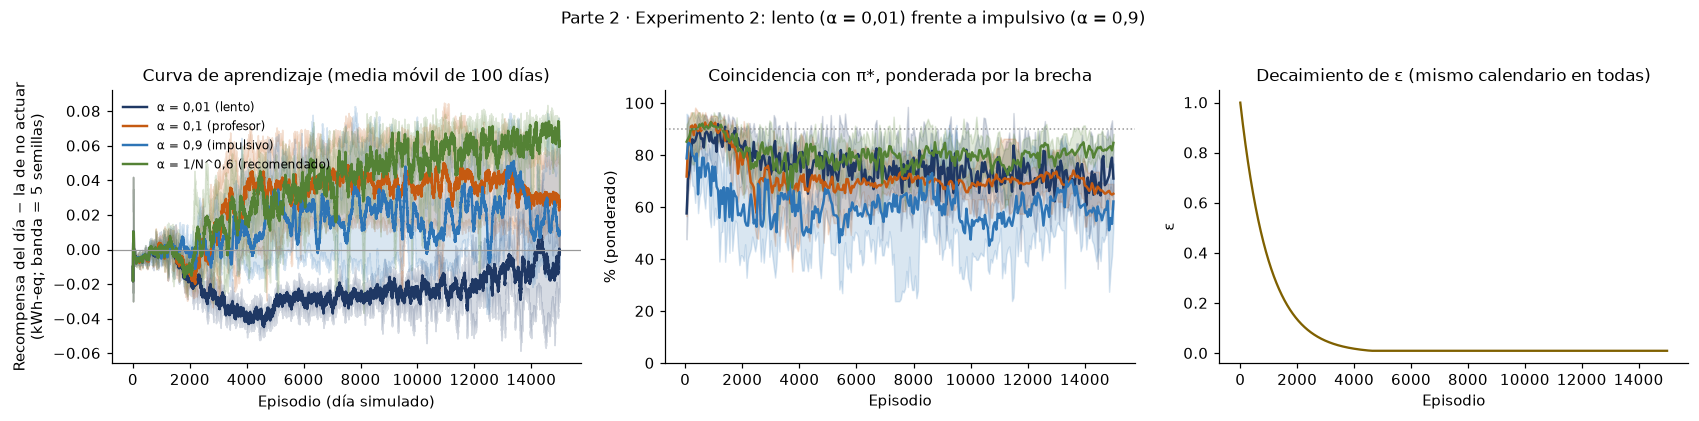

α = 0.01: oscilación de la curva (últimos 2.000 días) = 0.018 kWh-eq · salto medio de la coincidencia ponderada entre mediciones (últimos 2.000 días) = 10.5 puntos
α = 0.1: oscilación de la curva (últimos 2.000 días) = 0.010 kWh-eq · salto medio de la coincidencia ponderada entre mediciones (últimos 2.000 días) = 1.4 puntos
α = 0.9: oscilación de la curva (últimos 2.000 días) = 0.023 kWh-eq · salto medio de la coincidencia ponderada entre mediciones (últimos 2.000 días) = 5.5 puntos
α = 1/N^0.6: oscilación de la curva (últimos 2.000 días) = 0.009 kWh-eq · salto medio de la coincidencia ponderada entre mediciones (últimos 2.000 días) = 2.2 puntos


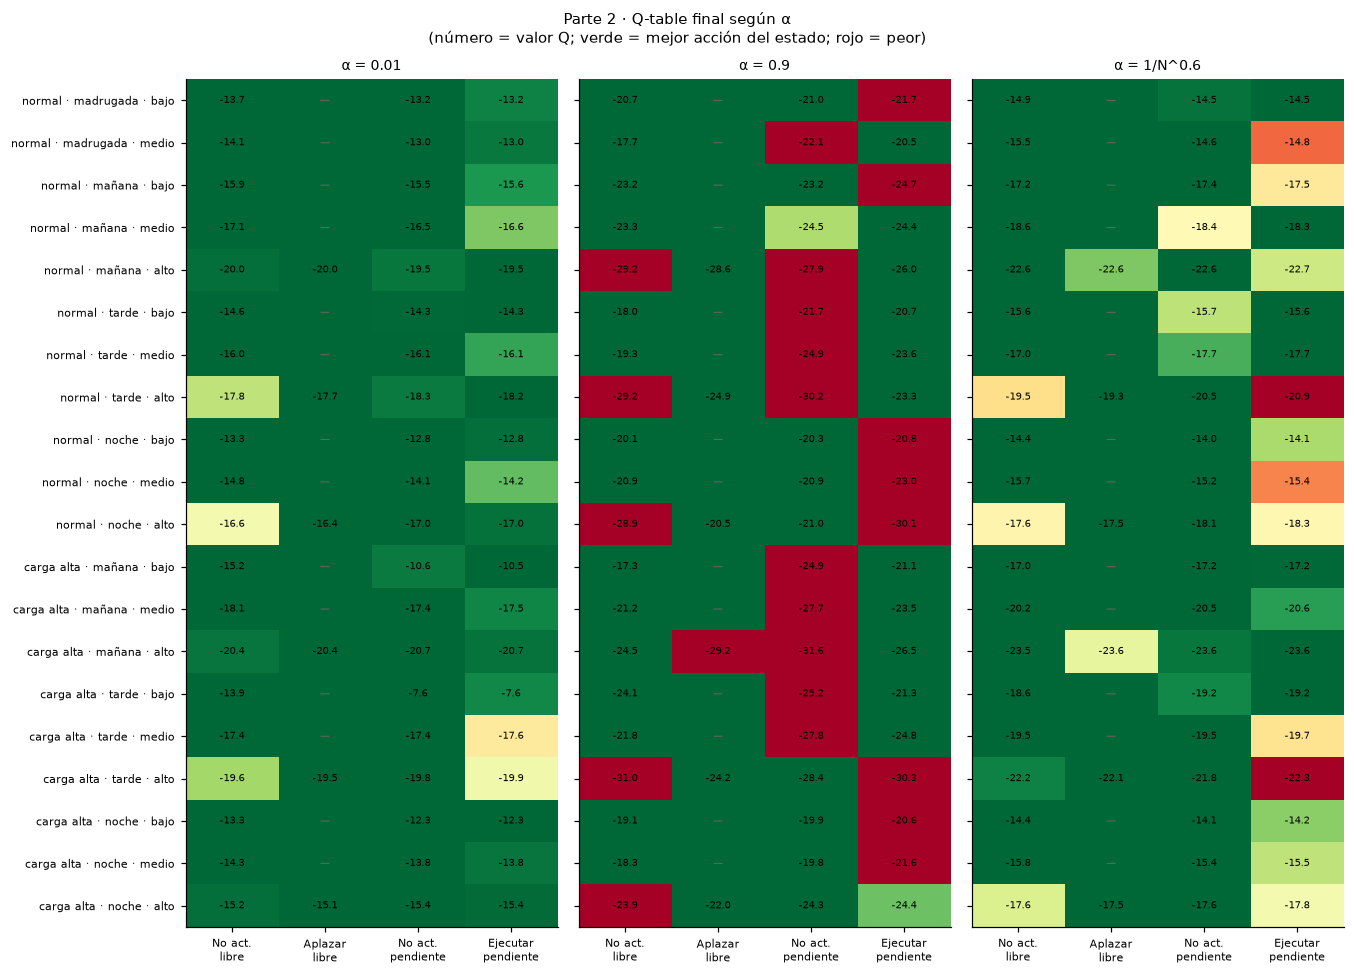

In [11]:
G = {0.95: BASE}
for g in (0.5, 0.9, 0.99):
    G[g] = correr(mU, ENV_R, f"γ = {g}", pi_ref=PI[("umbral", g)], pesos=BRECHA[("umbral", g)], gamma=g, **REC)
for g in (0.5, 0.9, 0.99):
    TABLA.append(resumen_corridas(G[g], mU, PI[("umbral", g)], f"g{str(g).replace('.', 'p')}", f"Parte 2 · γ = {g}"))
fig_experimento({f"γ = {g}": G[g] for g in (0.5, 0.9, 0.95, 0.99)}, "Q5_parte2_gamma.png",
                "Parte 2 · Experimento 1: miope (γ = 0,5) frente a paciente (γ = 0,99)")
fig_heatmaps([(f"γ = {g}", q_medio(G[g]), mU) for g in (0.5, 0.95, 0.99)], "Q6_parte2_gamma_heatmap.png",
             "Parte 2 · Q-table final según γ")
for g in (0.5, 0.95, 0.99):
    pg = pol_consenso(G[g], mU); tag = str(g).replace('.', 'p')
    print(f"γ = {g}: aplaza en {(pg == 1).sum()} estados, ejecuta en {(pg == 2).sum()}; π*(γ) aplaza en {(PI[('umbral', g)] == 1).sum()} "
          f"y ejecuta en {(PI[('umbral', g)] == 2).sum()} · Q mínimo {q_medio(G[g])[mU.VALID].min():.1f}")
    reg(f"g{tag}_ql_aplaza", int((pg == 1).sum()), es(int((pg == 1).sum()), 0)); reg(f"g{tag}_ql_ejecuta", int((pg == 2).sum()), es(int((pg == 2).sum()), 0))
    reg(f"g{tag}_vi_ejecuta", int((PI[("umbral", g)] == 2).sum()), es(int((PI[("umbral", g)] == 2).sum()), 0))
    reg(f"g{tag}_qmin", float(q_medio(G[g])[mU.VALID].min()), es(float(q_medio(G[g])[mU.VALID].min()), 1))

A_ = {ALPHA_REC: BASE}
for a_ in (0.01, 0.1, 0.9):
    A_[a_] = correr(mU, ENV_R, f"α = {a_} (15.000 días)", pi_ref=piU, pesos=wU, alpha=a_, n_ep=N_EP_REC)
for a_ in (0.01, 0.1, 0.9):
    TABLA.append(resumen_corridas(A_[a_], mU, piU, f"a{str(a_).replace('.', 'p')}", f"Parte 2 · α = {a_}"))
fig_experimento({"α = 0,01 (lento)": A_[0.01], "α = 0,1 (profesor)": A_[0.1], "α = 0,9 (impulsivo)": A_[0.9],
                 "α = 1/N^0,6 (recomendado)": A_[ALPHA_REC]}, "Q7_parte2_alpha.png",
                "Parte 2 · Experimento 2: lento (α = 0,01) frente a impulsivo (α = 0,9)")
for a_, k in ((0.01, "a0p01"), (0.1, "a0p1"), (0.9, "a0p9"), (ALPHA_REC, "arec")):
    fin = np.array([pd.Series(c["g"]).rolling(VENTANA).mean().values[-2000:] for c in A_[a_]])
    disp = fin.std(1).mean()
    salto = np.mean([np.abs(np.diff(c["acierto_w"][-40:])).mean() for c in A_[a_]])
    reg(f"{k}_disp", disp, es(disp, 3) + " kWh-eq"); reg(f"{k}_salto", salto, es(salto, 1) + " puntos")
    print(f"α = {a_}: oscilación de la curva (últimos 2.000 días) = {disp:.3f} kWh-eq · salto medio de la coincidencia "
          f"ponderada entre mediciones (últimos 2.000 días) = {salto:.1f} puntos")
fig_heatmaps([(f"α = {a_}", q_medio(A_[a_]), mU) for a_ in (0.01, 0.9, ALPHA_REC)], "Q9_parte2_alpha_heatmap.png",
             "Parte 2 · Q-table final según α")

## Parte 3 · El arquitecto del mundo: cuantiles frente a K-Means

Se reentrena el agente recomendado con las tres definiciones de estado del Paso 2. Cada definición tiene su propia π\*
(la iteración de valor sobre su propio MDP) y su propio ΔE: el 40 % del exceso medio de las horas que esa definición
llama «alto». Todas se evalúan con la cuenta real en mayo.

  Cuantiles (qcut)                          23.9 s · coincidencia  61.2 % · ponderada  63.6 % (rango 51–76) · llegan al 90 % ponderado: 0 de 5 semillas


  K-Means                                   23.8 s · coincidencia  76.9 % · ponderada  83.5 % (rango 79–90) · llegan al 90 % ponderado: 0 de 5 semillas
             Definición  Estados  Horas 'alto' (%)  ΔE (Wh)  π*: estados que aplazan  π* mayo · ahorro (%)  π* mayo · espera (h/día)  π* mayo · kWh movidos/día
       Cuantiles (qcut)       24            33.636  123.288                        1                 0.285                     5.538                      0.114
                K-Means       40             6.629  401.874                        6                 0.405                     4.577                      0.170
Umbral 60/200 Wh (base)       40            10.909  310.278                        6                 0.594                     7.154                      0.239


Horas del tercil alto (qcut) sin ninguna lectura sobre 200 Wh: 35.6 %


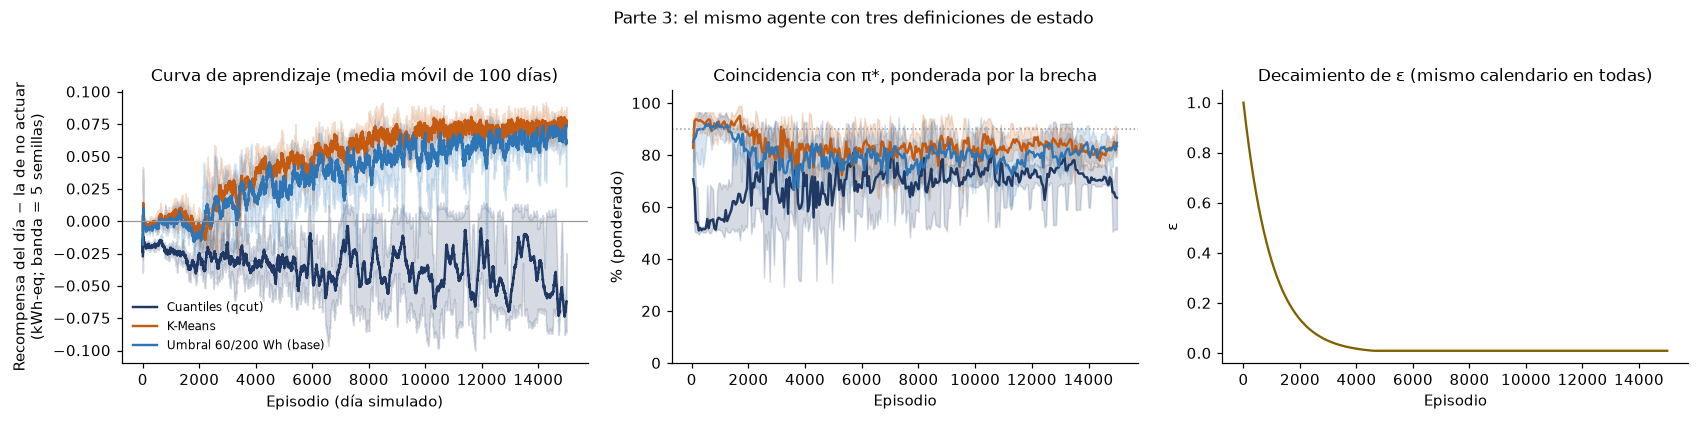

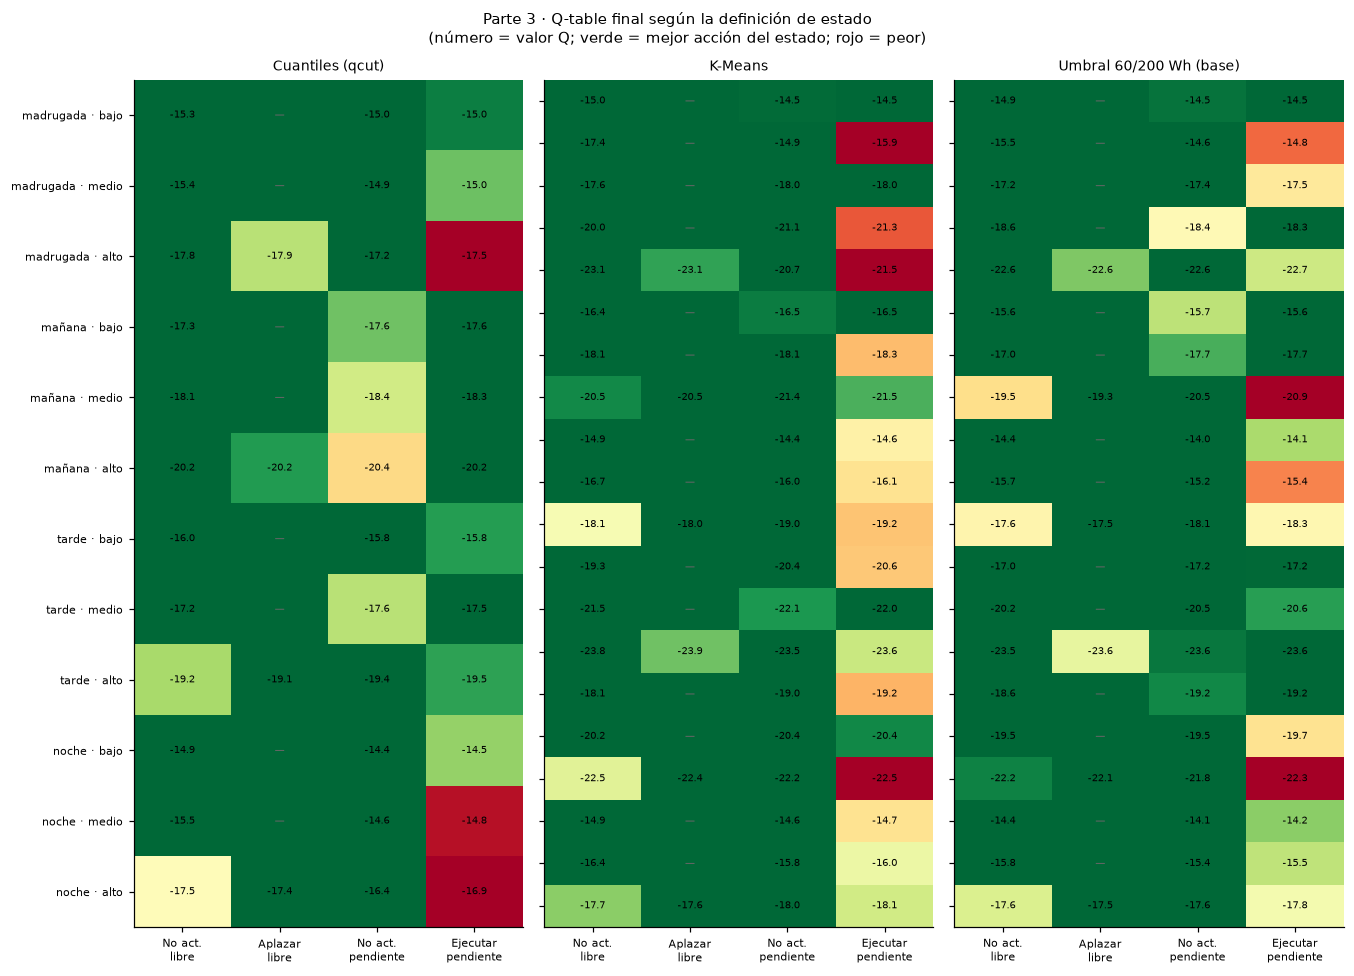

In [12]:
DEF_RES = {"umbral": BASE}
for k in ("qcut", "kmeans"):
    m = MDPS[k]; DEF_RES[k] = correr(m, EntornoReplica(m, TR), DEFS[k]["nombre"], pi_ref=PI[(k, GAMMA)], pesos=BRECHA[(k, GAMMA)], **REC)
    TABLA.append(resumen_corridas(DEF_RES[k], m, PI[(k, GAMMA)], f"p3_{k}", f"Parte 3 · {DEFS[k]['nombre']}"))
p3 = []
for k in ("qcut", "kmeans", "umbral"):
    m = MDPS[k]; rr = resumen_mayo(PI[(k, GAMMA)], m)
    p3.append({"Definición": DEFS[k]["nombre"], "Estados": m.nS, "Horas 'alto' (%)": DEFS[k]["pct_alto"], "ΔE (Wh)": m.DE,
               "π*: estados que aplazan": int((PI[(k, GAMMA)] == 1).sum()), "π* mayo · ahorro (%)": rr["ahorro"],
               "π* mayo · espera (h/día)": rr["espera"], "π* mayo · kWh movidos/día": rr["kwh_mov"]})
    reg(f"p3vi_{k}_ahorro", rr["ahorro"], es(rr["ahorro"], 2) + " %"); reg(f"p3vi_{k}_espera", rr["espera"], es(rr["espera"], 1) + " h/día")
    reg(f"p3vi_{k}_kwh", rr["kwh_mov"], es(rr["kwh_mov"], 2) + " kWh/día"); reg(f"p3vi_{k}_aplaz", rr["aplaz"], es(rr["aplaz"], 2))
df_p3 = pd.DataFrame(p3); print(df_p3.round(3).to_string(index=False))
alto_q = TR[TR.nivel_qcut == 2]; sin_exceso = (alto_q.exceso == 0).mean() * 100
print(f"Horas del tercil alto (qcut) sin ninguna lectura sobre 200 Wh: {sin_exceso:.1f} %")
reg("p3_qcut_sin_exceso", sin_exceso, es(sin_exceso) + " %")
fig_experimento({DEFS[k]["nombre"]: DEF_RES[k] for k in ("qcut", "kmeans", "umbral")}, "Q10_parte3_aprendizaje.png",
                "Parte 3: el mismo agente con tres definiciones de estado")
fig_heatmaps([(DEFS[k]["nombre"], q_medio(DEF_RES[k]), MDPS[k]) for k in ("qcut", "kmeans", "umbral")],
             "Q11_parte3_heatmap.png", "Parte 3 · Q-table final según la definición de estado")

## Parte 4 · El ingeniero de recompensas

El agente optimiza **exactamente** lo que se le pide. Sobre el problema base (agente recomendado) se cambia solo la
recompensa:

| Variante | Recompensa |
|---|---|
| Base | −tarifa · energía − λ · espera (contabilidad corregida del Taller 1) |
| **+1 por transacción** | 1 si aplaza o ejecuta; 0 si no actúa (sin importar el costo) |
| **Castigo por pérdida** | Ganancia neta del paso frente a no actuar; si es negativa, −1000 |
| *Extra: contabilidad ingenua* | La energía aplazada se cobra completa al ejecutarla (la trampa del Taller 1) |

Todas se evalúan con la **misma cuenta real** en mayo. Las curvas de recompensa están en unidades distintas, así que se
comparan además el ahorro real y los aplazamientos por episodio.

  +1 por transacción                        19.7 s · coincidencia  34.6 % · ponderada  26.3 % (rango 23–30) · llegan al 90 % ponderado: 0 de 5 semillas


  Castigo −1000 por pérdida                 17.5 s · coincidencia  10.0 % · ponderada   8.4 % (rango 2–14) · llegan al 90 % ponderado: 0 de 5 semillas


  Contabilidad ingenua                      16.6 s · coincidencia  72.3 % · ponderada  82.6 % (rango 79–84) · llegan al 90 % ponderado: 0 de 5 semillas


+1 por transacción: la política de consenso aplaza en 6 estados y ejecuta en 18
Castigo −1000 por pérdida: la política de consenso aplaza en 0 estados y ejecuta en 19
Contabilidad ingenua: la política de consenso aplaza en 5 estados y ejecuta en 6
Base: la política de consenso aplaza en 4 estados y ejecuta en 5


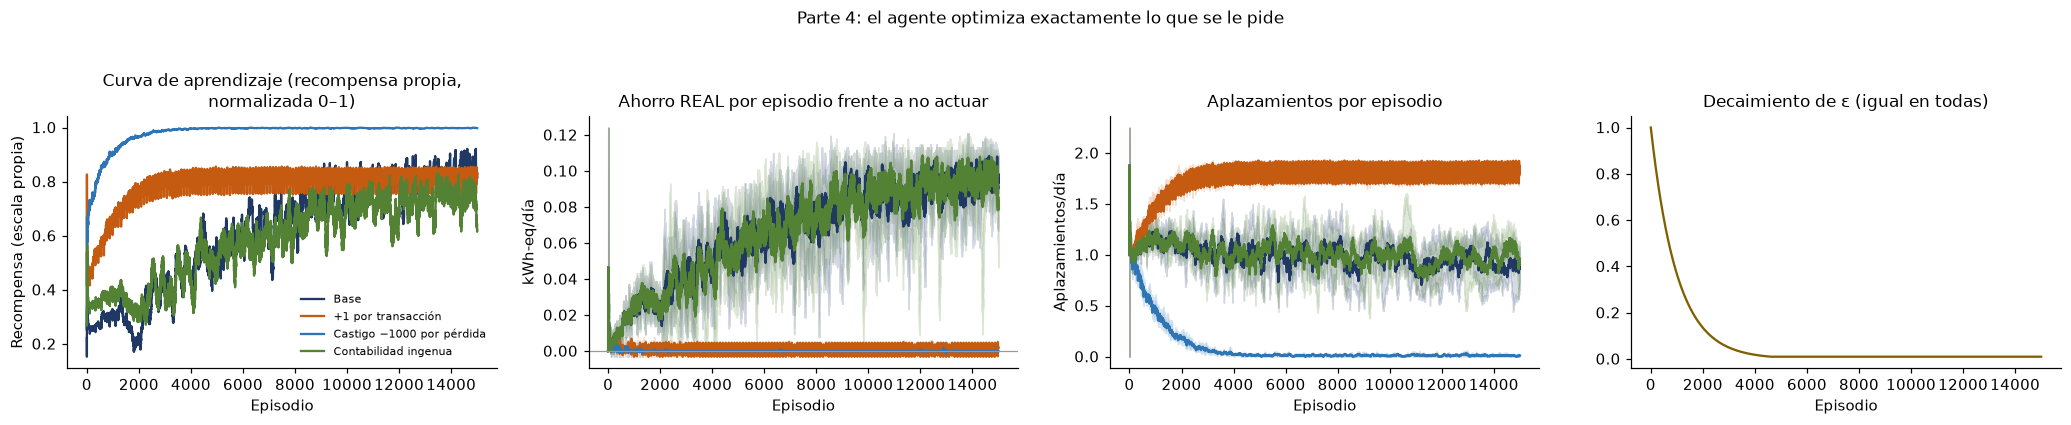

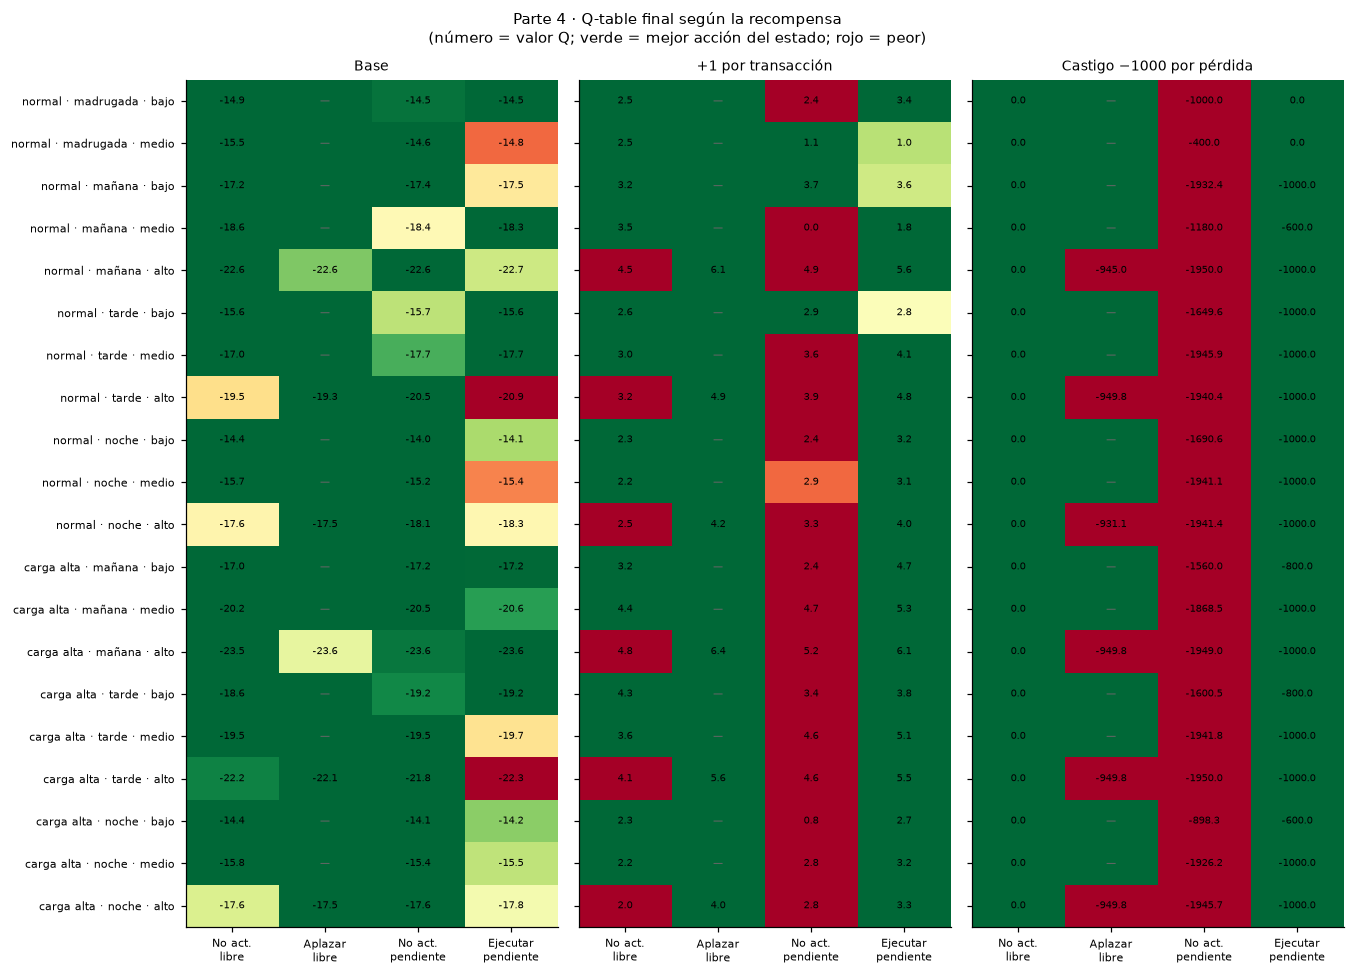

In [13]:
RECO = {"Base": BASE}
RECO["+1 por transacción"] = correr(mU, ENV_R, "+1 por transacción", pi_ref=piU, pesos=wU, recompensa="transaccion", **REC)
RECO["Castigo −1000 por pérdida"] = correr(mU, ENV_R, "Castigo −1000 por pérdida", pi_ref=piU, pesos=wU, recompensa="miedo", **REC)
RECO["Contabilidad ingenua"] = correr(mU, ENV_R, "Contabilidad ingenua", pi_ref=piU, pesos=wU, contab="ingenua", **REC)
claves4 = {"+1 por transacción": "p4_trans", "Castigo −1000 por pérdida": "p4_miedo", "Contabilidad ingenua": "p4_ing"}
for nom, k in claves4.items():
    TABLA.append(resumen_corridas(RECO[nom], mU, piU, k, f"Parte 4 · {nom}"))
for nom, k in list(claves4.items()) + [("Base", "base")]:
    pc4 = pol_consenso(RECO[nom], mU)
    reg(f"{k}_aplaza_est", int((pc4 == 1).sum()), es(int((pc4 == 1).sum()), 0)); reg(f"{k}_ejecuta_est", int((pc4 == 2).sum()), es(int((pc4 == 2).sum()), 0))
    print(f"{nom}: la política de consenso aplaza en {(pc4 == 1).sum()} estados y ejecuta en {(pc4 == 2).sum()}")

fig, axs = plt.subplots(1, 4, figsize=(19, 3.7))
for j, (nom, cor) in enumerate(RECO.items()):
    col = PALETA[j]
    banda(axs[1], cor, "ahorro", col, nom); banda(axs[2], cor, "aplz", col, nom)
    M = np.array([pd.Series(c["g"]).rolling(VENTANA, min_periods=1).mean().values for c in cor])
    M = (M - M.min()) / (M.max() - M.min() + 1e-12)
    axs[0].plot(M.mean(0), color=col, label=nom)
axs[0].set(title="Curva de aprendizaje (recompensa propia,\nnormalizada 0–1)", xlabel="Episodio", ylabel="Recompensa (escala propia)")
axs[1].axhline(0, color="#999", lw=0.8)
axs[1].set(title="Ahorro REAL por episodio frente a no actuar", xlabel="Episodio", ylabel="kWh-eq/día")
axs[2].set(title="Aplazamientos por episodio", xlabel="Episodio", ylabel="Aplazamientos/día")
axs[3].plot(BASE[0]["eps"], color="#7F6000"); axs[3].set(title="Decaimiento de ε (igual en todas)", xlabel="Episodio")
axs[0].legend(frameon=False, fontsize=7.5)
fig.suptitle("Parte 4: el agente optimiza exactamente lo que se le pide", fontsize=11, y=1.03)
fig.tight_layout(); fig.savefig(FIG / "Q12_parte4_recompensas.png", bbox_inches="tight"); plt.show()
fig_heatmaps([(nom, q_medio(cor), mU) for nom, cor in RECO.items() if nom != "Contabilidad ingenua"], "Q13_parte4_heatmap.png",
             "Parte 4 · Q-table final según la recompensa")

## La batalla en mayo y el resumen

Todas las configuraciones, evaluadas con su política voraz final en el mes que nunca vieron (media de las 5 semillas).
Para comparar el agente recomendado con π\* y con no actuar se usa bootstrap pareado por día (2.000 réplicas, semilla 42).

                       Configuración  Coincidencia (%)  Coincidencia ponderada (%)  Semillas que llegan al 90 %  Mayo · ahorro  Mayo · espera  Mayo · aplaz  Mayo · objetivo  Ahorro capturado de π* (%)
           Profesor · entorno modelo            54.615                      58.644                            0          0.194          2.777         1.062           19.079                      32.632
   Profesor · réplica de días reales            54.615                      67.341                            0          0.231          2.746         0.785           19.071                      38.947
        Recomendado · entorno modelo            66.923                      73.722                            1          0.200          5.908         0.846           19.093                      33.684
Recomendado · réplica de días reales            73.077                      84.750                            0          0.531          5.546         0.800           19.028                      89

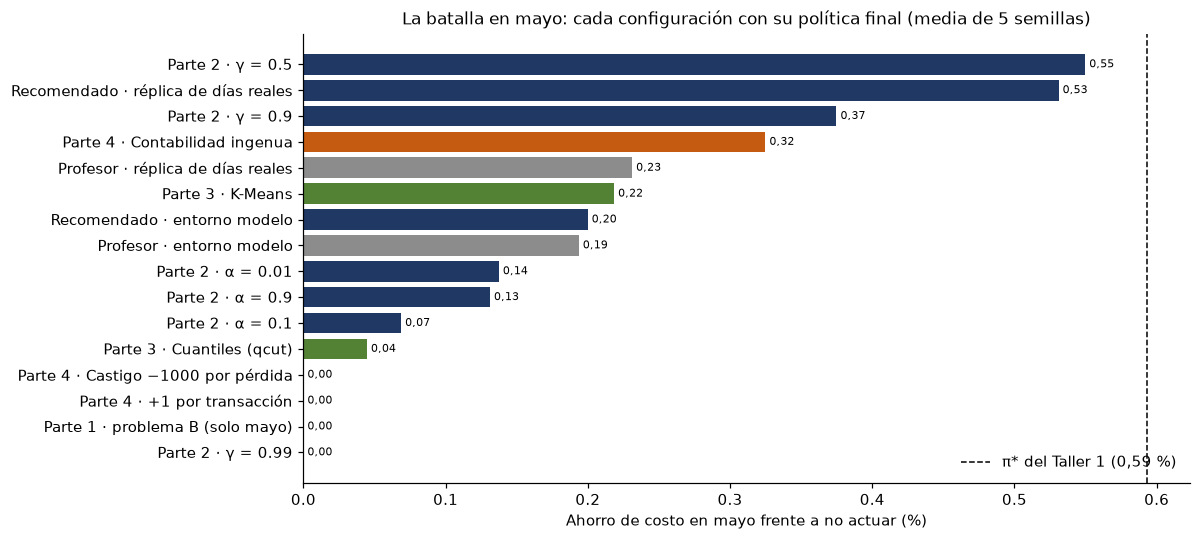

In [14]:
df_tabla = pd.DataFrame(TABLA)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
print(df_tabla.to_string(index=False))
df_tabla.to_csv("resumen_configuraciones.csv", index=False, encoding="utf-8")

def bootstrap(a, b, n=2000, seed=RS):
    rng = np.random.default_rng(seed); dif = (a - b).values; k = len(dif)
    reps = np.array([dif[rng.integers(0, k, k)].mean() for _ in range(n)])
    return dif.mean(), np.percentile(reps, 2.5), np.percentile(reps, 97.5)
obj = lambda r_: r_["diarios"].costo + LAMBDA * r_["diarios"].espera
r_pi, r_no = resumen_mayo(piU, mU), resumen_mayo(np.zeros(mU.nS, int), mU)
r_ql = resumen_mayo(pol_consenso(BASE, mU), mU)
reg("ql_cons_ahorro", r_ql["ahorro"], es(r_ql["ahorro"], 2) + " %"); reg("ql_cons_espera", r_ql["espera"], es(r_ql["espera"], 1) + " h/día")
for nom, rr, k in (("π*", r_pi, "pi"), ("No actuar", r_no, "no")):
    m_, lo, hi = bootstrap(obj(r_ql), obj(rr))
    sig = "sí" if (hi < 0 or lo > 0) else "no"
    print(f"Q-learning recomendado (consenso) menos {nom}: {m_:.4f} kWh-eq/día (IC {lo:.4f} a {hi:.4f}) → ¿se distingue? {sig}")
    reg(f"boot_ql_{k}", m_, f"{es(m_, 3)} kWh-eq/día (IC {es(lo, 3)} a {es(hi, 3)})"); reg(f"boot_ql_{k}_sig", sig, sig)

fig, ax = plt.subplots(figsize=(11, 5))
orden = df_tabla.sort_values("Mayo · ahorro")
cols = ["#C55A11" if "Parte 4" in c else ("#548235" if "Parte 3" in c else ("#7F6000" if "Parte 1" in c else
        ("#8C8C8C" if "Profesor" in c else AZUL))) for c in orden["Configuración"]]
ax.barh(orden["Configuración"], orden["Mayo · ahorro"], color=cols)
ax.axvline(r_pi["ahorro"], color="black", ls="--", lw=1, label=f"π* del Taller 1 ({es(r_pi['ahorro'], 2)} %)")
for y_, v in enumerate(orden["Mayo · ahorro"]):
    ax.text(max(v, 0), y_, f" {es(v, 2)}", va="center", fontsize=7.5)
ax.set_xlabel("Ahorro de costo en mayo frente a no actuar (%)"); ax.legend(frameon=False, loc="lower right")
ax.set_title("La batalla en mayo: cada configuración con su política final (media de 5 semillas)")
fig.tight_layout(); fig.savefig(FIG / "Q14_batalla_mayo.png"); plt.show()

## Exportación de cifras

In [15]:
Path("cifras.json").write_text(json.dumps({"meta": {"generado": time.strftime("%Y-%m-%d %H:%M"),
    "parametros": {"ALPHA": ALPHA, "ALPHA_REC": ALPHA_REC, "GAMMA": GAMMA, "EPS0": EPS0, "EPS_MIN": EPS_MIN, "DECAY": DECAY,
                   "N_EP": N_EP, "N_EP_REC": N_EP_REC, "SEMILLAS": SEMILLAS, "LAMBDA": LAMBDA, "R_PUNTA": R_PUNTA,
                   "F_DESPL": F_DESPL}}, "cifras": CIFRAS}, ensure_ascii=False, indent=1, default=float), encoding="utf-8")
print(f"cifras.json: {len(CIFRAS)} cifras · figuras: {sorted(p.name for p in FIG.glob('Q*.png'))}")

cifras.json: 330 cifras · figuras: ['Q10_parte3_aprendizaje.png', 'Q11_parte3_heatmap.png', 'Q12_parte4_recompensas.png', 'Q13_parte4_heatmap.png', 'Q14_batalla_mayo.png', 'Q1_base_aprendizaje.png', 'Q2_base_heatmap.png', 'Q3_parte1_aprendizaje.png', 'Q4_parte1_heatmap.png', 'Q5_parte2_gamma.png', 'Q6_parte2_gamma_heatmap.png', 'Q7_parte2_alpha.png', 'Q8_cortes_estados.png', 'Q9_parte2_alpha_heatmap.png']
